# Power Spectrum Analysis with NaMaster

Auto and cross power spectra for:
- **Proper motion map** (star, spin-1)
- **Stellar density map** (spin-0)
- **m10 / scanning strategy map** from Quaia (spin-0)


In [ ]:
from pathlib import Path

# Folder holding the input catalogues (quaia_G20.0_with_pmra_pmdec_corr.csv,
# gaia_qso_edata_5_params.csv, ...). Change this one line to relocate the data.
DATA_DIR = Path('../data')   # relative to notebooks/, i.e. <repo>/data

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import healpy as hp
import pymaster as nmt
import pandas as pd
from astropy.coordinates import SkyCoord
from astropy import units as u
from astropy.io import fits
from scipy.stats import chi2
import astropy.table as at

import matplotlib as mpl

from sbi_qpm.pixelization import Pixelize, pixelize_full_covariance
from sbi_qpm.data import compute_pixel_stats
from sbi_qpm.power_spectrum_analysis import (
    bandpower_to_full_cl,
    make_bins,
    make_spin1_field,
    make_spin0_field,
    apodize_mask,
    compute_power_spectrum,
)

plt.rcParams.update({
    'font.family': 'serif',
    'font.serif': ['Times New Roman', 'DejaVu Serif'],
    'mathtext.fontset': 'stix',
    'text.usetex': False,
})

plt.rcParams.update({
    'mathtext.fontset': 'cm',
    'mathtext.default': 'regular',
})

## Parameters

In [2]:
nside = 64
npix  = hp.nside2npix(nside)
nbin  = 1           # multipoles per band-power bin
lmax_hp = 3 * nside - 1  # healpy lmax for map2alm
N_SIMS = 500        # number of Monte Carlo realisations for variance
APOD_SCALE = 0.0   # apodisation scale in degrees
APOD_TYPE  = 'C1'


In [3]:
from sbi_qpm.geometry import SkyFunction
from sbi_qpm.pixelization import Pixelize
from sbi_qpm.power_spectrum_analysis import (
    make_bins, make_spin1_field, make_spin0_field,
    apodize_mask, compute_power_spectrum,
    estimate_noise_covariance, evaluate_cross_spectrum,
)
from sbi_qpm.plotting import plot_power_spectrum, plot_snr_per_ell
skyfunc = SkyFunction(nside)
pixelize = Pixelize(nside)

## Load data

In [4]:
# ── QSO / gaia data (used for scanning / m10 map) ──────────────────────────
quaia = pd.read_csv(DATA_DIR / 'quaia_G20.0_with_pmra_pmdec_corr.csv')

gaia    = pd.read_csv(DATA_DIR / 'gaia_qso_edata_5_params.csv')

quaia = quaia.merge(gaia[['source_id']], on='source_id', how='inner')


scanning = pd.read_csv(DATA_DIR / 'gaia_scanning.csv')

# ── Faint stars ─────────────────────────────────────────────────────────────
star = pd.concat([
    pd.read_csv(DATA_DIR / 'gaia_faint_stars_90.csv'),
    pd.read_csv(DATA_DIR / 'gaia_faint_stars_180.csv'),
    pd.read_csv(DATA_DIR / 'gaia_faint_stars_270.csv'),
    pd.read_csv(DATA_DIR / 'gaia_faint_stars_360.csv'),
], ignore_index=True)

print(f'QSO rows : {len(gaia)}')
print(f'Star rows: {len(star)}')

QSO rows : 1215942
Star rows: 6465890


## Build maps
### Stellar proper motion + density maps

In [5]:
gaia_ra  = gaia['ra'].values
gaia_dec = gaia['dec'].values
gaia_pmra  = gaia['pmra'].values
gaia_pmdec = gaia['pmdec'].values

gaia_sig_pmra  = gaia['pmra_error'].values
gaia_sig_pmdec = gaia['pmdec_error'].values 
gaia_pm_corr    = gaia['pmra_pmdec_corr'].values

gaia_theta = np.radians(90 - gaia_dec)
gaia_phi   = np.radians(gaia_ra)

sig_pmra_gaia  = gaia['pmra_error'].values
sig_pmdec_gaia = gaia['pmdec_error'].values

# Inverse-variance weights
w_pmra_gaia  = np.where(sig_pmra_gaia  > 0, 1.0 / sig_pmra_gaia**2,  0)
w_pmdec_gaia = np.where(sig_pmdec_gaia > 0, 1.0 / sig_pmdec_gaia**2, 0)

gaia_pmra_wm = pixelize.calculate_weighted_means(gaia_theta, gaia_phi, gaia_pmra, gaia_sig_pmra) 
gaia_pmdec_wm = pixelize.calculate_weighted_means(gaia_theta, gaia_phi, gaia_pmdec, gaia_sig_pmdec) 
sw_ra  = pixelize.sum_in_pixels(gaia_theta, gaia_phi, weights=1 / sig_pmra_gaia**2)
sw_dec = pixelize.sum_in_pixels(gaia_theta, gaia_phi, weights=1 / sig_pmdec_gaia**2)
cinv_rd = pixelize.sum_in_pixels(gaia_theta, gaia_phi,
              weights=gaia_pm_corr / (gaia_sig_pmra * gaia_sig_pmdec))
with np.errstate(invalid='ignore'):
    gaia_pm_corr_wm = np.where(
        (sw_ra > 0) & (sw_dec > 0),
        cinv_rd / np.sqrt(sw_ra * sw_dec),
        0.0
    )

n_per_pixel = pixelize.sum_in_pixels(gaia_theta, gaia_phi)

# Stellar density map

star_ra  = star['ra'].values
star_dec = star['dec'].values
star_theta = np.radians(90 - star_dec)
star_phi   = np.radians(star_ra)

nstar_per_pixel = pixelize.sum_in_pixels(star_theta, star_phi)

print('Gaia PM map range (ra)  :', gaia_pmra_wm.min(), gaia_pmra_wm.max())
print('Gaia PM map range (dec) :', gaia_pmdec_wm.min(), gaia_pmdec_wm.max())
print('Gaia density range      :', nstar_per_pixel.min(), nstar_per_pixel.max())


Gaia PM map range (ra)  : -4.67229351163996 2.6567091544556343
Gaia PM map range (dec) : -2.26543919006731 3.4057281639312023
Gaia density range      : 0.0 3252.0


In [6]:
# pixelize_full_covariance imported from sbi_qpm.pixelization
gaia_pmra_full, gaia_pmdec_full, gaia_sig_pmra_full, gaia_sig_pmdec_full, gaia_pm_corr_full=pixelize_full_covariance(
        gaia_theta, gaia_phi,
        gaia_pmra, gaia_pmdec,
        gaia_sig_pmra, gaia_sig_pmdec, gaia_pm_corr,
        nside,
    )

In [7]:
# ── Stellar proper-motion maps (full 2×2 covariance weighted) ───────────────
star_pmra_vals  = star['pmra'].values
star_pmdec_vals = star['pmdec'].values
star_pmra_err   = star['pmra_error'].values
star_pmdec_err  = star['pmdec_error'].values
star_pm_corr    = star['pmra_pmdec_corr'].values

star_pmra_wm, star_pmdec_wm, star_sig_pmra, star_sig_pmdec, _ = pixelize_full_covariance(
    star_theta, star_phi,
    star_pmra_vals, star_pmdec_vals,
    star_pmra_err, star_pmdec_err, star_pm_corr,
    nside,
)

star_w_ra  = np.where(star_sig_pmra  > 0, 1.0 / star_sig_pmra**2,  0.0)
star_w_dec = np.where(star_sig_pmdec > 0, 1.0 / star_sig_pmdec**2, 0.0)



/tmp/ipykernel_624013/52383849.py:15: RuntimeWarning: divide by zero encountered in divide
  star_w_ra  = np.where(star_sig_pmra  > 0, 1.0 / star_sig_pmra**2,  0.0)
/tmp/ipykernel_624013/52383849.py:16: RuntimeWarning: divide by zero encountered in divide
  star_w_dec = np.where(star_sig_pmdec > 0, 1.0 / star_sig_pmdec**2, 0.0)


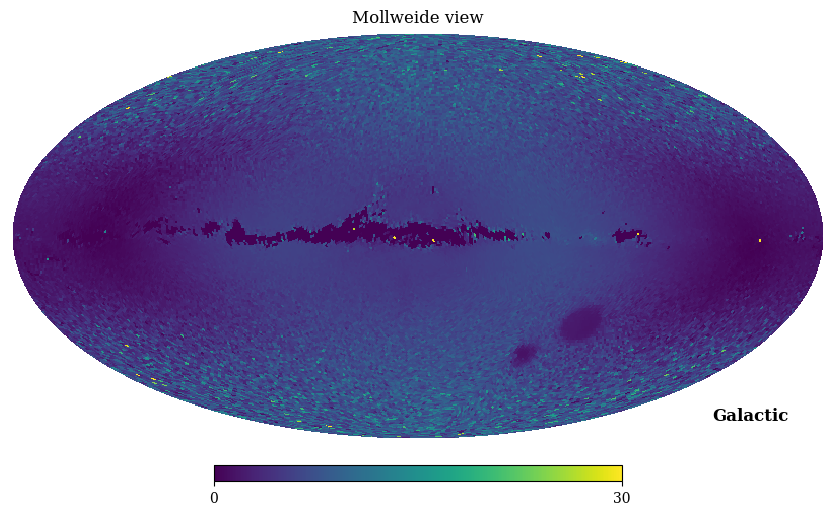

In [8]:
hp.mollview(np.sqrt(star_pmra_wm**2 + star_pmdec_wm**2), coord= ['C', 'G'], min = 0, max = 30)

### Scanning / m10 map (Quaia scanning strategy)

The DataLink service will not be available on Thursday 10 September between 09:45 and 14:00 due to maintenance.
(49152,)


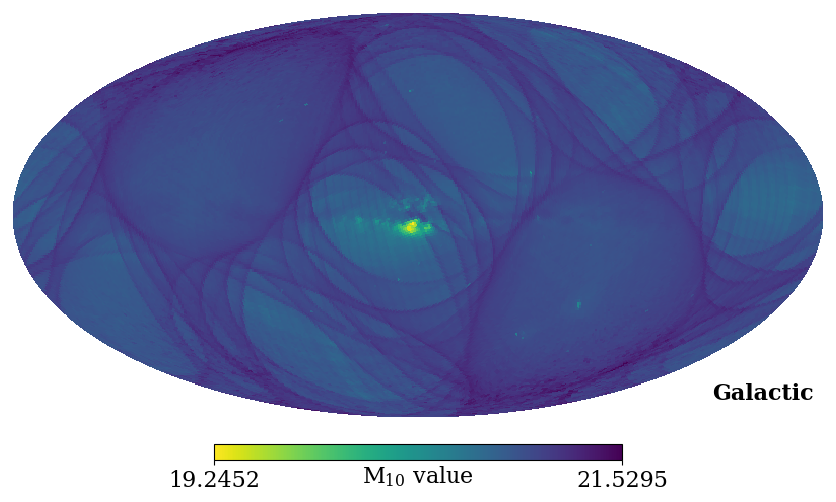

In [9]:
from gaiaunlimited.selectionfunctions import DR3SelectionFunctionTCG
from gaiaunlimited.utils import get_healpix_centers


# Load the default all-sky M10 map (stored at HEALPix order 7)
sf = DR3SelectionFunctionTCG()

# Get the centers of all HEALPix pixels at order 6 (NSIDE=64, 49152 pixels)
coords_order6 = get_healpix_centers(6)

# Query the M10 value at each pixel center
# Use a reference magnitude (e.g. G=21) — the map returns completeness,
# but we want M10 directly from the internal map
m10_col  = sf.m10map[:, 2]          # M10 values, one per order-7 pixel
# m10map rows are already sorted by nested pixel index at order 7
# Build a proper NSIDE=128 healpy array (NESTED)
nside_in = 128
npix_in  = hp.nside2npix(nside_in)   # 196608

m10_fullmap = np.full(npix_in, hp.UNSEEN)
pix_indices = sf.m10map[:, 1].astype(int)   # pixel numbers at order 7
m10_fullmap[pix_indices] = m10_col
nside_out = 64

# Now ud_grade works — degrade from NSIDE=128 to NSIDE=64
m10_map = hp.ud_grade(m10_fullmap, nside_out=nside,
                          order_in='NESTED', order_out='NESTED')
m10_map = hp.reorder(m10_map, n2r=True)  # convert from NESTED to RING ordering

print(m10_map.shape)   # (49152,)

# Visualize
hp.mollview(m10_map,
            coord=['C', 'G'],
            cmap='viridis_r',
            unit=r'$M_{10}$ value',
            title='',
            fontsize={'xlabel': 16, 'ylabel': 16, 'title': 16, 'cbar_label': 16}
            )

# Increase colorbar tick and unit-label sizes
fig = plt.gcf()
if len(fig.axes) > 1:
    cbar_ax = fig.axes[-1]
    cbar_ax.tick_params(axis='both', labelsize=16)
    cbar_ax.xaxis.label.set_size(16)
    cbar_ax.yaxis.label.set_size(16)

    # Re-set tick and label fonts explicitly
    for label in cbar_ax.get_xticklabels() + cbar_ax.get_yticklabels():
        label.set_fontfamily('serif')
        label.set_fontsize(16)
plt.savefig(r'output/scanning.pdf')

## Build masks

In [10]:
theta = np.radians(90 - gaia_dec)  
phi = np.radians(gaia_ra)  

npix = hp.nside2npix(nside)

 # Get the pixel indices
pix_indices = np.arange(npix)

theta_grid, phi_grid = hp.pix2ang( nside, pix_indices, lonlat = False ) 
ra_grid = phi_grid*180./np.pi
dec_grid = 90 -(theta_grid*180./np.pi)  

icrs_coords = SkyCoord(ra_grid * u.deg, dec_grid * u.deg, frame='icrs')
galactic_coords = icrs_coords.galactic
mask_galactic = np.abs(galactic_coords.b.deg) > 0

In [11]:


# Gaia proper motion: pixel must have valid (non-zero) weighted mean
mask_gaia = (
    (gaia_pmra_full  != 0) & (gaia_pmdec_full  != 0)  &
    mask_galactic
)
# m10: pixel must have a valid (non-UNSEEN) value
mask_m10 = (m10_map > hp.UNSEEN + 1) & mask_galactic

# Stellar density: pixel must contain at least one star
mask_sdens = (nstar_per_pixel > 0) & mask_galactic

mask_star_pm = (star_w_ra > 0) & (star_w_dec > 0) & mask_galactic

# Combined mask for cross-correlations (intersection)
mask_cross = mask_gaia & mask_sdens & mask_m10 & mask_star_pm



mean_sdens = np.sum(nstar_per_pixel * mask_cross) / np.sum(mask_cross)
mean_m10   = np.sum(m10_map * mask_cross)            / np.sum(mask_cross)

nstar_delta = np.where(mask_cross, (nstar_per_pixel - mean_sdens) / mean_sdens, 0.0)
nstar_ms    = np.where(mask_cross,   nstar_per_pixel - mean_sdens, 0.0)

m10_ms    = np.where(mask_cross,   m10_map         - mean_m10,   0.0)


# Apodise for NaMaster
apod_gaia   = nmt.mask_apodization(mask_gaia.astype(float),   APOD_SCALE, APOD_TYPE)
apod_m10    = nmt.mask_apodization(mask_m10.astype(float),    APOD_SCALE, APOD_TYPE)
apod_sdens  = nmt.mask_apodization(mask_sdens.astype(float),  APOD_SCALE, APOD_TYPE)
apod_cross  = nmt.mask_apodization(mask_cross.astype(float),  APOD_SCALE, APOD_TYPE)

apod_gaia   = hp.ud_grade(apod_gaia,  nside_out=nside)
apod_m10    = hp.ud_grade(apod_m10,   nside_out=nside)
apod_sdens  = hp.ud_grade(apod_sdens, nside_out=nside)
apod_cross  = hp.ud_grade(apod_cross, nside_out=nside)

# Zero out UNSEEN pixels in the m10 map before passing to NaMaster
m10_map_clean = np.where(mask_m10, m10_map, 0.0)

f_sky_gaia  = np.mean(apod_gaia**2)
f_sky_m10   = np.mean(apod_m10**2)
f_sky_sdens = np.mean(apod_sdens**2)
f_sky_cross = np.mean(apod_cross**2)
print(f'f_sky: gaia={f_sky_gaia:.3f}  m10={f_sky_m10:.3f}  '
      f'sdens={f_sky_sdens:.3f}  cross={f_sky_cross:.3f}')

# pm_corr field: mean-subtract gaia_pm_corr_full within mask_gaia
mean_corr = np.sum(gaia_pm_corr_full * mask_gaia) / max(np.sum(mask_gaia), 1)
corr_ms   = np.where(mask_gaia, gaia_pm_corr_full - mean_corr, 0.0)


f_sky: gaia=0.879  m10=1.000  sdens=0.979  cross=0.879


## NaMaster binning and fields

In [12]:
bins = nmt.NmtBin.from_nside_linear(nside, nbin)
ells = bins.get_effective_ells()
print(f'Effective ells (first 10): {ells[:10]}')

# ── Spin-1 : stellar proper motion ──────────────────────────────────────────
# field_pm = nmt.NmtField(mask_gaia, [gaia_pmra_wm, gaia_pmdec_wm], spin=1)
field_pm    = nmt.NmtField(mask_gaia, [-gaia_pmdec_full, gaia_pmra_full], spin=1)


# ── Spin-0 : stellar density ─────────────────────────────────────────────────
field_sdens = nmt.NmtField(apod_sdens, [nstar_ms])

# ── Spin-0 : m10 map ─────────────────────────────────────────────────────────
field_m10 = nmt.NmtField(apod_m10, [m10_ms])

# ── Cross-correlation fields (joint mask) ────────────────────────────────────
# field_pm_x    = nmt.NmtField(mask_gaia, [gaia_pmra_wm, gaia_pmdec_wm], spin=1)
field_pm_x    = nmt.NmtField(mask_gaia, [-gaia_pmdec_full, gaia_pmra_full], spin=1)

field_sdens_x = nmt.NmtField(mask_gaia, [nstar_ms])
field_m10_x   = nmt.NmtField(mask_gaia, [m10_ms])

# ── Spin-0 : pm_corr map ────────────────────────────────────────────────────
# Reuse apod_gaia mask (corr is valid wherever gaia PM is valid)
field_corr   = nmt.NmtField(apod_gaia, [corr_ms])
field_corr_x = nmt.NmtField(mask_gaia, [corr_ms])


Effective ells (first 10): [ 2.  3.  4.  5.  6.  7.  8.  9. 10. 11.]


## Auto power spectra (NaMaster, ell ≥ 2)

In [13]:
# ── 1.  Stellar PM  ×  Stellar PM  (spin-1 auto) ────────────────────────────
ws_pmpm = nmt.NmtWorkspace()
ws_pmpm.compute_coupling_matrix(field_pm, field_pm, bins)

cl_pmpm_coupled   = nmt.compute_coupled_cell(field_pm, field_pm)
cl_pmpm_decoupled = ws_pmpm.decouple_cell(cl_pmpm_coupled)
# Indices: [0]=EE  [1]=EB  [2]=BE  [3]=BB
cl_pm_EE = cl_pmpm_decoupled[0]
cl_pm_BB = cl_pmpm_decoupled[3]

print(f'PM auto EE (first 5): {cl_pm_EE[:5]}')
print(f'PM auto BB (first 5): {cl_pm_BB[:5]}')

PM auto EE (first 5): [3.14333796e-05 1.63997953e-05 8.12304011e-06 1.09279648e-06
 1.07486192e-05]
PM auto BB (first 5): [3.38328603e-06 4.39331376e-05 8.02056182e-06 3.90314953e-05
 1.42642802e-05]


## Cross power spectra (NaMaster, ell ≥ 2)

For spin-1 × spin-0 NaMaster returns 2 components: [0] = E×T, [1] = B×T

In [14]:
# ── 4.  Stellar PM  ×  Stellar density  (spin-1 × spin-0) ──────────────────
ws_pmsd = nmt.NmtWorkspace()
ws_pmsd.compute_coupling_matrix(field_pm_x, field_sdens_x, bins)

cl_pmsd_coupled   = nmt.compute_coupled_cell(field_pm_x, field_sdens_x)
cl_pmsd_decoupled = ws_pmsd.decouple_cell(cl_pmsd_coupled)
cl_pm_x_sdens_E = cl_pmsd_decoupled[0]   # E × density
cl_pm_x_sdens_B = cl_pmsd_decoupled[1]   # B × density

print(f'PM × sdens  E (first 5): {cl_pm_x_sdens_E[:5] *1e3}')
print(f'PM × sdens  B (first 5): {cl_pm_x_sdens_B[:5] * 1e3}')

PM × sdens  E (first 5): [248.57711386  11.84927834  46.01156288   0.65947697 -46.17691605]
PM × sdens  B (first 5): [-135.14948841  304.29018185   41.08593424  -64.54105697   -5.75567026]


In [15]:
# ── 5.  Stellar PM  ×  m10  (spin-1 × spin-0) ──────────────────────────────
ws_pmm10 = nmt.NmtWorkspace()
ws_pmm10.compute_coupling_matrix(field_pm_x, field_m10_x, bins)

cl_pmm10_coupled   = nmt.compute_coupled_cell(field_pm_x, field_m10_x)
cl_pmm10_decoupled = ws_pmm10.decouple_cell(cl_pmm10_coupled)
cl_pm_x_m10_E = cl_pmm10_decoupled[0]    # E × m10
cl_pm_x_m10_B = cl_pmm10_decoupled[1]    # B × m10

print(f'PM × m10   E (first 5): {cl_pm_x_m10_E[:5]}')
print(f'PM × m10   B (first 5): {cl_pm_x_m10_B[:5]}')

PM × m10   E (first 5): [ 4.97874227e-05  8.45883712e-06 -8.42275678e-05  4.23030578e-07
  1.33260626e-04]
PM × m10   B (first 5): [-3.99902577e-05  9.16672596e-05 -5.30328081e-05 -9.90108529e-06
  8.19446698e-06]


In [16]:
# ── 6.  QSO PM  x  Stellar PM  (spin-1 x spin-1) ────────────────────────────
mask_cross_pm = mask_gaia & mask_star_pm
apod_cross_pm = nmt.mask_apodization(mask_cross_pm.astype(float),
                                      APOD_SCALE, APOD_TYPE)
apod_cross_pm = hp.ud_grade(apod_cross_pm, nside_out=nside)

field_qpm_x = nmt.NmtField(apod_cross_pm, [-gaia_pmdec_wm,  gaia_pmra_wm],  spin=1)
field_spm_x = nmt.NmtField(apod_cross_pm, [-star_pmdec_wm,  star_pmra_wm],  spin=1)

# Auto-spectrum of stellar PM (needed for MC fiducial)
ws_spmpm = nmt.NmtWorkspace()
ws_spmpm.compute_coupling_matrix(field_spm_x, field_spm_x, bins)
cl_spmpm_coupled   = nmt.compute_coupled_cell(field_spm_x, field_spm_x)
cl_spmpm_decoupled = ws_spmpm.decouple_cell(cl_spmpm_coupled)
cl_spm_EE = cl_spmpm_decoupled[0]
cl_spm_BB = cl_spmpm_decoupled[3]

# Cross-spectrum
ws_pmxpm = nmt.NmtWorkspace()
ws_pmxpm.compute_coupling_matrix(field_qpm_x, field_spm_x, bins)
cl_pmxpm_coupled   = nmt.compute_coupled_cell(field_qpm_x, field_spm_x)
cl_pmxpm_decoupled = ws_pmxpm.decouple_cell(cl_pmxpm_coupled)

# spin-1 x spin-1 returns [EE, EB, BE, BB]
cl_qpm_x_spm_EE = cl_pmxpm_decoupled[0]
cl_qpm_x_spm_BB = cl_pmxpm_decoupled[3]

print(f'Stellar PM auto  EE (first 5): {cl_spm_EE[:5]}')
print(f'QSO PM x Stellar PM  EE (first 5): {cl_qpm_x_spm_EE[:5]}')
print(f'QSO PM x Stellar PM  BB (first 5): {cl_qpm_x_spm_BB[:5]}')


Stellar PM auto  EE (first 5): [ 1.69357701  1.71576927  0.03224258  0.04689265 -0.00922318]
QSO PM x Stellar PM  EE (first 5): [ 2.27382259e-03  8.99474881e-04  9.81403970e-05  9.61582903e-06
 -8.14747845e-05]
QSO PM x Stellar PM  BB (first 5): [-0.00330343 -0.0004195   0.0012166  -0.00024579  0.00023803]


In [17]:
_ws = nmt.NmtWorkspace()
_ws.compute_coupling_matrix(field_sdens_x, field_sdens_x, bins)
cl_sdens_auto = _ws.decouple_cell(
    nmt.compute_coupled_cell(field_sdens_x, field_sdens_x))[0]

_ws.compute_coupling_matrix(field_m10_x, field_m10_x, bins)
cl_m10_auto = _ws.decouple_cell(
    nmt.compute_coupled_cell(field_m10_x, field_m10_x))[0]

## Variance via Monte Carlo simulation

Strategy:
1. Use the measured power spectra as fiducial inputs.
2. Generate `N_SIMS` Gaussian random field realisations per map.
3. Compute NaMaster power spectra for each realisation.
4. The variance across realisations gives the 1-sigma error bars.

> For cross-spectra the two maps are simulated with their auto-spectra only
> (zero cross-correlation assumed as a null test).  Replace the fiducial
> cross-Cl below if a non-zero signal is expected.

In [18]:
# bandpower_to_full_cl imported from sbi_qpm.power_spectrum_analysis
n_ells   = len(ells)
lmax_sim = 3 * nside - 1

fid_pm_EE = bandpower_to_full_cl(ells, cl_pm_EE,     lmax_sim)
fid_pm_BB = bandpower_to_full_cl(ells, cl_pm_BB,     lmax_sim)
fid_sdens = bandpower_to_full_cl(ells, cl_sdens_auto, lmax_sim)
fid_m10   = bandpower_to_full_cl(ells, cl_m10_auto,   lmax_sim)

fid_pm_spin1 = np.array([np.zeros(lmax_sim + 1),
                          fid_pm_EE,
                          fid_pm_BB,
                          np.zeros(lmax_sim + 1)])

fid_spm_EE = bandpower_to_full_cl(ells, cl_spm_EE, lmax_sim)
fid_spm_BB = bandpower_to_full_cl(ells, cl_spm_BB, lmax_sim)

print('Fiducial spectra built.')

Fiducial spectra built.


In [19]:
rng = np.random.default_rng(42)

sims_pm_EE        = np.zeros((N_SIMS, n_ells))
sims_pm_BB        = np.zeros((N_SIMS, n_ells))
sims_sdens        = np.zeros((N_SIMS, n_ells))
sims_m10          = np.zeros((N_SIMS, n_ells))
sims_pm_x_sdens_E = np.zeros((N_SIMS, n_ells))
sims_pm_x_sdens_B = np.zeros((N_SIMS, n_ells))
sims_pm_x_m10_E   = np.zeros((N_SIMS, n_ells))
sims_pm_x_m10_B   = np.zeros((N_SIMS, n_ells))

print(f'Running {N_SIMS} simulations...')

for i in range(N_SIMS):
    # ── Gaussian random maps ────────────────────────────────────────────────
    alm_E_pm = hp.synalm(fid_pm_EE, lmax=lmax_sim)
    alm_B_pm = hp.synalm(fid_pm_BB, lmax=lmax_sim)
    m_theta, m_phi = hp.alm2map_spin([alm_E_pm, alm_B_pm], nside, spin=1, lmax=lmax_sim)
    sim_pmra  =  m_phi
    sim_pmdec = -m_theta

    sim_sdens_raw = hp.synfast(fid_sdens, nside, lmax=lmax_sim)
    sim_m10_raw   = hp.synfast(fid_m10,   nside, lmax=lmax_sim)
    sim_sdens_ms  = sim_sdens_raw - np.sum(sim_sdens_raw * mask_gaia) / np.sum(mask_gaia)
    sim_m10_ms    = sim_m10_raw   - np.sum(sim_m10_raw   * mask_gaia) / np.sum(mask_gaia)

    # ── NaMaster fields ─────────────────────────────────────────────────────
    f_pm_i   = nmt.NmtField(mask_gaia, [-sim_pmdec, sim_pmra], spin=1)
    f_pmx_i  = nmt.NmtField(mask_gaia, [-sim_pmdec, sim_pmra], spin=1)
    f_sdx_i  = nmt.NmtField(mask_gaia, [sim_sdens_ms])
    f_m10x_i = nmt.NmtField(mask_gaia, [sim_m10_ms])

    # ── Decouple ─────────────────────────────────────────────────────────────
    cl_pm_i    = ws_pmpm.decouple_cell(nmt.compute_coupled_cell(f_pm_i,  f_pm_i))
    cl_pmsd_i  = ws_pmsd.decouple_cell(nmt.compute_coupled_cell(f_pmx_i, f_sdx_i))
    cl_pmm10_i = ws_pmm10.decouple_cell(nmt.compute_coupled_cell(f_pmx_i, f_m10x_i))

    sims_pm_EE[i]        = cl_pm_i[0]
    sims_pm_BB[i]        = cl_pm_i[3]
    sims_pm_x_sdens_E[i] = cl_pmsd_i[0]
    sims_pm_x_sdens_B[i] = cl_pmsd_i[1]
    sims_pm_x_m10_E[i]   = cl_pmm10_i[0]
    sims_pm_x_m10_B[i]   = cl_pmm10_i[1]

    if (i + 1) % 50 == 0:
        print(f'  {i + 1}/{N_SIMS}')

print('Done.')

Running 500 simulations...
  50/500
  100/500
  150/500
  200/500
  250/500
  300/500
  350/500
  400/500
  450/500
  500/500
Done.


In [20]:
std_pm_EE        = np.std(sims_pm_EE,        axis=0)
std_pm_BB        = np.std(sims_pm_BB,        axis=0)
std_sdens        = np.std(sims_sdens,        axis=0)
std_m10          = np.std(sims_m10,          axis=0)
std_pm_x_sdens_E = np.std(sims_pm_x_sdens_E, axis=0)
std_pm_x_sdens_B = np.std(sims_pm_x_sdens_B, axis=0)
std_pm_x_m10_E   = np.std(sims_pm_x_m10_E,   axis=0)
std_pm_x_m10_B   = np.std(sims_pm_x_m10_B,   axis=0)

ERR_pm_EE        = std_pm_EE
ERR_pm_BB        = std_pm_BB
ERR_pm_x_sdens_E = std_pm_x_sdens_E
ERR_pm_x_sdens_B = std_pm_x_sdens_B
ERR_pm_x_m10_E   = std_pm_x_m10_E
ERR_pm_x_m10_B   = std_pm_x_m10_B

print('Variance estimated from simulations.')

Variance estimated from simulations.


In [21]:
ells_full = ells   # ell >= 2 (NaMaster range)

CL_pm_EE         = cl_pm_EE
CL_pm_BB         = cl_pm_BB
CL_pm_x_sdens_E  = cl_pm_x_sdens_E
CL_pm_x_sdens_B  = cl_pm_x_sdens_B
CL_pm_x_m10_E    = cl_pm_x_m10_E
CL_pm_x_m10_B    = cl_pm_x_m10_B

ERR_pm_EE        = std_pm_EE
ERR_pm_BB        = std_pm_BB
ERR_pm_x_sdens_E = std_pm_x_sdens_E
ERR_pm_x_sdens_B = std_pm_x_sdens_B
ERR_pm_x_m10_E   = std_pm_x_m10_E
ERR_pm_x_m10_B   = std_pm_x_m10_B

print('ell array:', ells_full[:5], '...', ells_full[-5:])

ell array: [2. 3. 4. 5. 6.] ... [187. 188. 189. 190. 191.]


In [22]:
# ── Monte Carlo variance for QSO PM x Stellar PM ────────────────────────────
sims_qpm_x_spm_EE = np.zeros((N_SIMS, n_ells))
sims_qpm_x_spm_BB = np.zeros((N_SIMS, n_ells))

print(f'Running {N_SIMS} simulations for QSO PM x Stellar PM ...')
for i in range(N_SIMS):
    alm_E_q = hp.synalm(fid_pm_EE,  lmax=lmax_sim)
    alm_B_q = hp.synalm(fid_pm_BB,  lmax=lmax_sim)
    alm_E_s = hp.synalm(fid_spm_EE, lmax=lmax_sim)
    alm_B_s = hp.synalm(fid_spm_BB, lmax=lmax_sim)

    mth_q, mph_q = hp.alm2map_spin([alm_E_q, alm_B_q], nside, spin=1, lmax=lmax_sim)
    mth_s, mph_s = hp.alm2map_spin([alm_E_s, alm_B_s], nside, spin=1, lmax=lmax_sim)
    sim_pmra_q =  mph_q;  sim_pmdec_q = -mth_q
    sim_pmra_s =  mph_s;  sim_pmdec_s = -mth_s

    f_q = nmt.NmtField(apod_cross_pm, [-sim_pmdec_q, sim_pmra_q], spin=1)
    f_s = nmt.NmtField(apod_cross_pm, [-sim_pmdec_s, sim_pmra_s], spin=1)

    cl_i = ws_pmxpm.decouple_cell(nmt.compute_coupled_cell(f_q, f_s))
    sims_qpm_x_spm_EE[i] = cl_i[0]
    sims_qpm_x_spm_BB[i] = cl_i[3]

    if (i + 1) % 50 == 0:
        print(f'  {i+1}/{N_SIMS}')

std_qpm_x_spm_EE = np.std(sims_qpm_x_spm_EE, axis=0)
std_qpm_x_spm_BB = np.std(sims_qpm_x_spm_BB, axis=0)

CL_qpm_x_spm_EE  = cl_qpm_x_spm_EE
CL_qpm_x_spm_BB  = cl_qpm_x_spm_BB
ERR_qpm_x_spm_EE = std_qpm_x_spm_EE
ERR_qpm_x_spm_BB = std_qpm_x_spm_BB

print('Done.')

Running 500 simulations for QSO PM x Stellar PM ...
  50/500
  100/500
  150/500
  200/500
  250/500
  300/500
  350/500
  400/500
  450/500
  500/500
Done.


## Fully NaMaster: dipole + higher multipoles (ell=1 via custom NmtBin)

In [23]:
# ── Custom NmtBin: ell=1 as its own bandpower (index 0), then nbin=1 per ell ─
lmax_nmt = 3 * nside - 1
ells_arr = np.arange(lmax_nmt + 1, dtype=np.int32)
bpws     = np.full(lmax_nmt + 1, -1, dtype=np.int32)
bpws[1]  = 0                    # dipole: bandpower 0
band_idx = 1
for ell in range(2, lmax_nmt + 1):
    bpws[ell] = band_idx
    band_idx += 1
bins_d1 = nmt.NmtBin(ells=ells_arr, bpws=bpws,
                      weights=np.ones(lmax_nmt + 1), lmax=lmax_nmt)
ells_d1 = bins_d1.get_effective_ells()
print(f'bins_d1 first 5 ells: {ells_d1[:5]}')   # should start at 1

# ── Joint boolean mask (no apodization) ──────────────────────────────────────
mask_all = (mask_gaia & mask_star_pm & mask_cross).astype(float)
print(f'f_sky = {mask_all.mean():.3f}')

# ── NaMaster fields (purify_e/b not supported for spin-1) ────────────────────
f_qpm_d1   = nmt.NmtField(mask_all, [-gaia_pmdec_wm, gaia_pmra_wm], spin=1)
f_sdens_d1 = nmt.NmtField(mask_all, [nstar_ms])
f_m10_d1   = nmt.NmtField(mask_all, [m10_ms])
f_spm_d1   = nmt.NmtField(mask_all, [-star_pmdec_wm, star_pmra_wm], spin=1)
f_corr_d1  = nmt.NmtField(mask_all, [corr_ms])

# ── Workspaces ────────────────────────────────────────────────────────────────
print('Computing coupling matrices...')
ws_d1_auto  = nmt.NmtWorkspace()
ws_d1_auto.compute_coupling_matrix(f_qpm_d1, f_qpm_d1,   bins_d1)
ws_d1_sdens = nmt.NmtWorkspace()
ws_d1_sdens.compute_coupling_matrix(f_qpm_d1, f_sdens_d1, bins_d1)
ws_d1_m10   = nmt.NmtWorkspace()
ws_d1_m10.compute_coupling_matrix(f_qpm_d1,   f_m10_d1,   bins_d1)
ws_d1_spm   = nmt.NmtWorkspace()
ws_d1_spm.compute_coupling_matrix(f_qpm_d1,   f_spm_d1,   bins_d1)
ws_d1_pmcorr = nmt.NmtWorkspace()
ws_d1_pmcorr.compute_coupling_matrix(f_qpm_d1, f_corr_d1, bins_d1)
ws_d1_corrm10 = nmt.NmtWorkspace()
ws_d1_corrm10.compute_coupling_matrix(f_corr_d1, f_m10_d1, bins_d1)
ws_d1_corr_auto = nmt.NmtWorkspace()
ws_d1_corr_auto.compute_coupling_matrix(f_corr_d1, f_corr_d1, bins_d1)
print('Done.')


bins_d1 first 5 ells: [1. 2. 3. 4. 5.]
f_sky = 0.879
Computing coupling matrices...
Done.


In [24]:
# ── Data power spectra ────────────────────────────────────────────────────────
def decouple_d1(ws, f1, f2):
    return ws.decouple_cell(nmt.compute_coupled_cell(f1, f2))

# Auto: QSO PM x QSO PM  -> [EE, EB, BE, BB]
cl_d1_auto  = decouple_d1(ws_d1_auto,  f_qpm_d1, f_qpm_d1)
# Cross: QSO PM x stellar density  -> [E, B]
cl_d1_sdens = decouple_d1(ws_d1_sdens, f_qpm_d1, f_sdens_d1)
# Cross: QSO PM x m10  -> [E, B]
cl_d1_m10   = decouple_d1(ws_d1_m10,   f_qpm_d1, f_m10_d1)
# Cross: QSO PM x stellar PM  -> [EE, EB, BE, BB]
cl_d1_spm   = decouple_d1(ws_d1_spm,   f_qpm_d1, f_spm_d1)

# Stellar PM auto-spectrum using mask_all (same mask as MC) -> correct fiducial amplitude
ws_d1_spm_auto = nmt.NmtWorkspace()
ws_d1_spm_auto.compute_coupling_matrix(f_spm_d1, f_spm_d1, bins_d1)
cl_d1_spm_auto = ws_d1_spm_auto.decouple_cell(nmt.compute_coupled_cell(f_spm_d1, f_spm_d1))
cl_d1_spm_auto_EE = cl_d1_spm_auto[0]
cl_d1_spm_auto_BB = cl_d1_spm_auto[3]

# QSO PM auto-spectrum fiducial from this pipeline (mask_all)
cl_d1_auto_EE_fid = cl_d1_auto[0]
cl_d1_auto_BB_fid = cl_d1_auto[3]

CL_d1_auto_EE = cl_d1_auto[0];   CL_d1_auto_BB = cl_d1_auto[3]
CL_d1_sdens_E = cl_d1_sdens[0];  CL_d1_sdens_B = cl_d1_sdens[1]
CL_d1_m10_E   = cl_d1_m10[0];    CL_d1_m10_B   = cl_d1_m10[1]
CL_d1_spm_EE  = cl_d1_spm[0];    CL_d1_spm_BB  = cl_d1_spm[3]

print(f'Auto   EE dipole: {CL_d1_auto_EE[0]*1e6:.4f}  BB: {CL_d1_auto_BB[0]*1e6:.4f}  (uas^2/yr^2)')
print(f'x sdens E dipole: {CL_d1_sdens_E[0]*1e3:.4f}  B: {CL_d1_sdens_B[0]*1e3:.4f}')
print(f'x m10   E dipole: {CL_d1_m10_E[0]:.4e}    B: {CL_d1_m10_B[0]:.4e}')
print(f'x spm  EE dipole: {CL_d1_spm_EE[0]*1e6:.4f}  BB: {CL_d1_spm_BB[0]*1e6:.4f}  (uas^2/yr^2)')
print(f'Stellar PM auto EE dipole: {cl_d1_spm_auto_EE[0]*1e6:.4f}  (fiducial for MC)')

# Cross: QSO PM x pm_corr  -> [E, B]
cl_d1_pmcorr  = decouple_d1(ws_d1_pmcorr,  f_qpm_d1,  f_corr_d1)
# Cross: pm_corr x m10  -> [T] (spin-0 x spin-0)
cl_d1_corrm10 = decouple_d1(ws_d1_corrm10, f_corr_d1, f_m10_d1)
# Auto: pm_corr (needed as MC fiducial)
cl_d1_corr_auto = decouple_d1(ws_d1_corr_auto, f_corr_d1, f_corr_d1)

CL_d1_pmcorr_E  = cl_d1_pmcorr[0];   CL_d1_pmcorr_B  = cl_d1_pmcorr[1]
CL_d1_corrm10   = cl_d1_corrm10[0]

print(f'x corr  E dipole: {CL_d1_pmcorr_E[0]:.4e}  B: {CL_d1_pmcorr_B[0]:.4e}')
print(f'corr x m10 dipole: {CL_d1_corrm10[0]:.4e}')



Auto   EE dipole: 85.5129  BB: 29.8448  (uas^2/yr^2)
x sdens E dipole: 1548.2954  B: -28.0823
x m10   E dipole: -1.7800e-04    B: -9.6309e-07
x spm  EE dipole: -11088.5345  BB: 21712.9314  (uas^2/yr^2)
Stellar PM auto EE dipole: 107724599.1849  (fiducial for MC)
x corr  E dipole: 6.6985e-04  B: -8.2042e-04
corr x m10 dipole: -1.1389e-03


In [25]:
# ── Monte Carlo simulations for error bars ────────────────────────────────────
# Build fiducials from the same mask_all pipeline (not the apodized one)
fid_d1_qpm_EE  = bandpower_to_full_cl(ells_d1[1:], cl_d1_auto_EE_fid[1:],  lmax_nmt)
fid_d1_qpm_BB  = bandpower_to_full_cl(ells_d1[1:], cl_d1_auto_BB_fid[1:],  lmax_nmt)
fid_d1_spm_EE  = bandpower_to_full_cl(ells_d1[1:], cl_d1_spm_auto_EE[1:],  lmax_nmt)
fid_d1_spm_BB  = bandpower_to_full_cl(ells_d1[1:], cl_d1_spm_auto_BB[1:],  lmax_nmt)
fid_d1_sdens   = bandpower_to_full_cl(ells[ells <= lmax_nmt], cl_sdens_auto[ells <= lmax_nmt], lmax_nmt)
fid_d1_m10     = bandpower_to_full_cl(ells[ells <= lmax_nmt], cl_m10_auto  [ells <= lmax_nmt], lmax_nmt)
fid_d1_corr    = bandpower_to_full_cl(ells_d1[1:], np.maximum(cl_d1_corr_auto[0][1:], 0), lmax_nmt)

n_ells_d1 = len(ells_d1)

sims_d1_auto_EE  = np.zeros((N_SIMS, n_ells_d1))
sims_d1_auto_BB  = np.zeros((N_SIMS, n_ells_d1))
sims_d1_sdens_E  = np.zeros((N_SIMS, n_ells_d1))
sims_d1_sdens_B  = np.zeros((N_SIMS, n_ells_d1))
sims_d1_m10_E    = np.zeros((N_SIMS, n_ells_d1))
sims_d1_m10_B    = np.zeros((N_SIMS, n_ells_d1))
sims_d1_spm_EE   = np.zeros((N_SIMS, n_ells_d1))
sims_d1_spm_BB   = np.zeros((N_SIMS, n_ells_d1))
sims_d1_pmcorr_E = np.zeros((N_SIMS, n_ells_d1))
sims_d1_pmcorr_B = np.zeros((N_SIMS, n_ells_d1))
sims_d1_corrm10  = np.zeros((N_SIMS, n_ells_d1))

print(f'Running {N_SIMS} simulations (fully NaMaster, ell=1 included)...')
for i in range(N_SIMS):
    # QSO PM: spin-1 realisation from mask_all fiducial
    alm_E_q = hp.synalm(fid_d1_qpm_EE, lmax=lmax_nmt)
    alm_B_q = hp.synalm(fid_d1_qpm_BB, lmax=lmax_nmt)
    mth_q, mph_q = hp.alm2map_spin([alm_E_q, alm_B_q], nside, spin=1, lmax=lmax_nmt)
    sim_pmra_q =  mph_q;  sim_pmdec_q = -mth_q

    # Stellar PM: independent spin-1 realisation from stellar auto fiducial
    alm_E_s = hp.synalm(fid_d1_spm_EE, lmax=lmax_nmt)
    alm_B_s = hp.synalm(fid_d1_spm_BB, lmax=lmax_nmt)
    mth_s, mph_s = hp.alm2map_spin([alm_E_s, alm_B_s], nside, spin=1, lmax=lmax_nmt)
    sim_pmra_s =  mph_s;  sim_pmdec_s = -mth_s

    # Scalar fields: mean-subtract within mask
    sim_sdens_raw = hp.synfast(fid_d1_sdens, nside, lmax=lmax_nmt, verbose=False)
    sim_m10_raw   = hp.synfast(fid_d1_m10,   nside, lmax=lmax_nmt, verbose=False)
    sim_sdens_ms  = sim_sdens_raw - np.sum(sim_sdens_raw * mask_all) / np.sum(mask_all)
    sim_m10_ms    = sim_m10_raw   - np.sum(sim_m10_raw   * mask_all) / np.sum(mask_all)
    sim_corr_raw  = hp.synfast(fid_d1_corr, nside, lmax=lmax_nmt, verbose=False)
    sim_corr_ms   = sim_corr_raw  - np.sum(sim_corr_raw  * mask_all) / np.sum(mask_all)

    # NaMaster fields (same mask as data)
    f_q_i   = nmt.NmtField(mask_all, [-sim_pmdec_q, sim_pmra_q], spin=1)
    f_s_i   = nmt.NmtField(mask_all, [-sim_pmdec_s, sim_pmra_s], spin=1)
    f_sd_i  = nmt.NmtField(mask_all, [sim_sdens_ms])
    f_m10_i = nmt.NmtField(mask_all, [sim_m10_ms])
    f_corr_i= nmt.NmtField(mask_all, [sim_corr_ms])

    cl_auto_i  = ws_d1_auto.decouple_cell(nmt.compute_coupled_cell(f_q_i,  f_q_i))
    cl_sdens_i = ws_d1_sdens.decouple_cell(nmt.compute_coupled_cell(f_q_i, f_sd_i))
    cl_m10_i   = ws_d1_m10.decouple_cell(nmt.compute_coupled_cell(f_q_i,   f_m10_i))
    cl_spm_i   = ws_d1_spm.decouple_cell(nmt.compute_coupled_cell(f_q_i,   f_s_i))
    cl_pmcorr_i = ws_d1_pmcorr.decouple_cell(nmt.compute_coupled_cell(f_q_i,   f_corr_i))
    cl_corrm10_i= ws_d1_corrm10.decouple_cell(nmt.compute_coupled_cell(f_corr_i,f_m10_i))

    sims_d1_auto_EE[i]  = cl_auto_i[0];   sims_d1_auto_BB[i]  = cl_auto_i[3]
    sims_d1_sdens_E[i]  = cl_sdens_i[0];  sims_d1_sdens_B[i]  = cl_sdens_i[1]
    sims_d1_m10_E[i]    = cl_m10_i[0];    sims_d1_m10_B[i]    = cl_m10_i[1]
    sims_d1_spm_EE[i]   = cl_spm_i[0];    sims_d1_spm_BB[i]   = cl_spm_i[3]
    sims_d1_pmcorr_E[i]  = cl_pmcorr_i[0];  sims_d1_pmcorr_B[i]  = cl_pmcorr_i[1]
    sims_d1_corrm10[i]   = cl_corrm10_i[0]

    if (i + 1) % 50 == 0:
        print(f'  {i+1}/{N_SIMS}')

ERR_d1_auto_EE  = np.std(sims_d1_auto_EE,  axis=0)
ERR_d1_auto_BB  = np.std(sims_d1_auto_BB,  axis=0)
ERR_d1_sdens_E  = np.std(sims_d1_sdens_E,  axis=0)
ERR_d1_sdens_B  = np.std(sims_d1_sdens_B,  axis=0)
ERR_d1_m10_E    = np.std(sims_d1_m10_E,    axis=0)
ERR_d1_m10_B    = np.std(sims_d1_m10_B,    axis=0)
ERR_d1_spm_EE   = np.std(sims_d1_spm_EE,   axis=0)
ERR_d1_spm_BB   = np.std(sims_d1_spm_BB,   axis=0)
ERR_d1_pmcorr_E  = np.std(sims_d1_pmcorr_E, axis=0)
ERR_d1_pmcorr_B  = np.std(sims_d1_pmcorr_B, axis=0)
ERR_d1_corrm10   = np.std(sims_d1_corrm10,  axis=0)

print('Done.')


Running 500 simulations (fully NaMaster, ell=1 included)...


/tmp/ipykernel_624013/262269372.py:40: HealpyDeprecationWarning: "verbose" was deprecated in version 1.15.0 and will be removed in a future version. 
  sim_sdens_raw = hp.synfast(fid_d1_sdens, nside, lmax=lmax_nmt, verbose=False)
/tmp/ipykernel_624013/262269372.py:41: HealpyDeprecationWarning: "verbose" was deprecated in version 1.15.0 and will be removed in a future version. 
  sim_m10_raw   = hp.synfast(fid_d1_m10,   nside, lmax=lmax_nmt, verbose=False)
/tmp/ipykernel_624013/262269372.py:44: HealpyDeprecationWarning: "verbose" was deprecated in version 1.15.0 and will be removed in a future version. 
  sim_corr_raw  = hp.synfast(fid_d1_corr, nside, lmax=lmax_nmt, verbose=False)


  50/500
  100/500
  150/500
  200/500
  250/500
  300/500
  350/500
  400/500
  450/500
  500/500
Done.


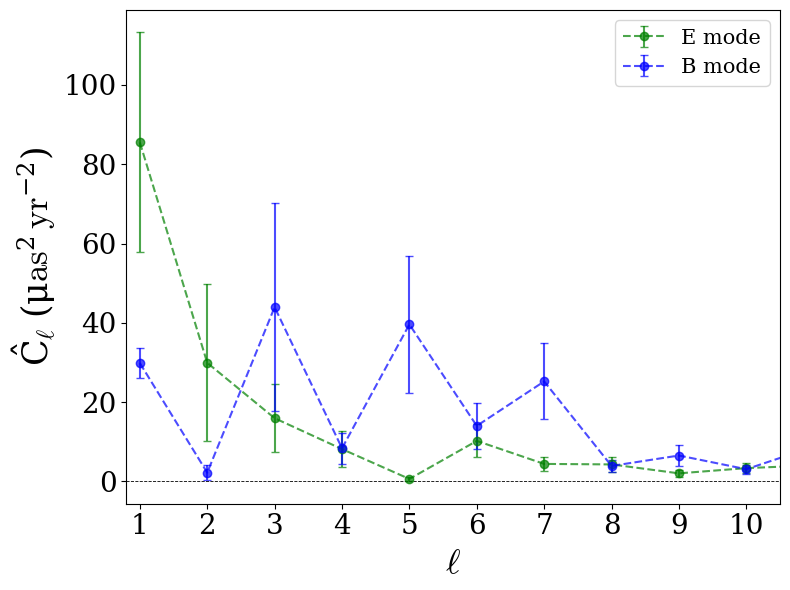

Auto QSO PM x QSO PM:
  E mode: chi2/dof = 48.50/10  p = 0.0000  (5.03 sigma)
  B mode: chi2/dof = 105.48/10  p = 0.0000  (inf sigma)


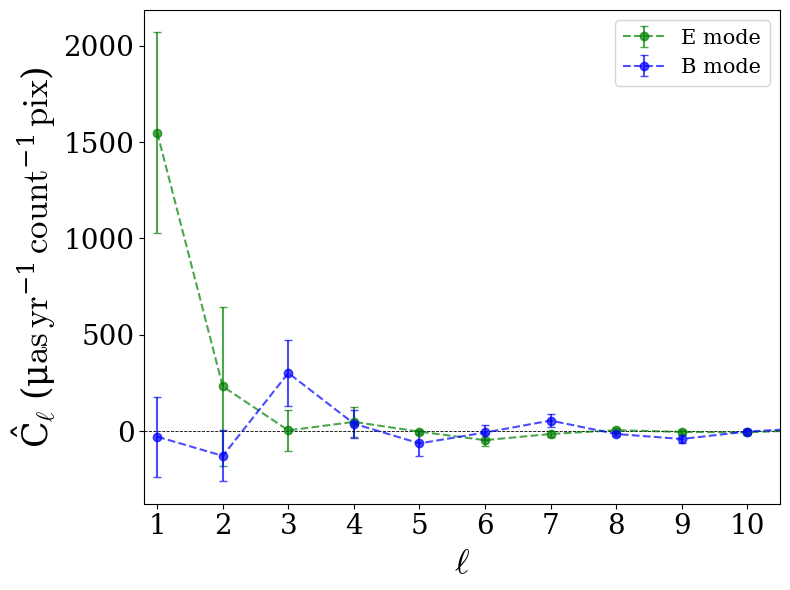

QSO PM x stellar density:
  E mode: chi2/dof = 13.36/10  p = 0.2043  (1.27 sigma)
  B mode: chi2/dof = 14.38/10  p = 0.1564  (1.42 sigma)


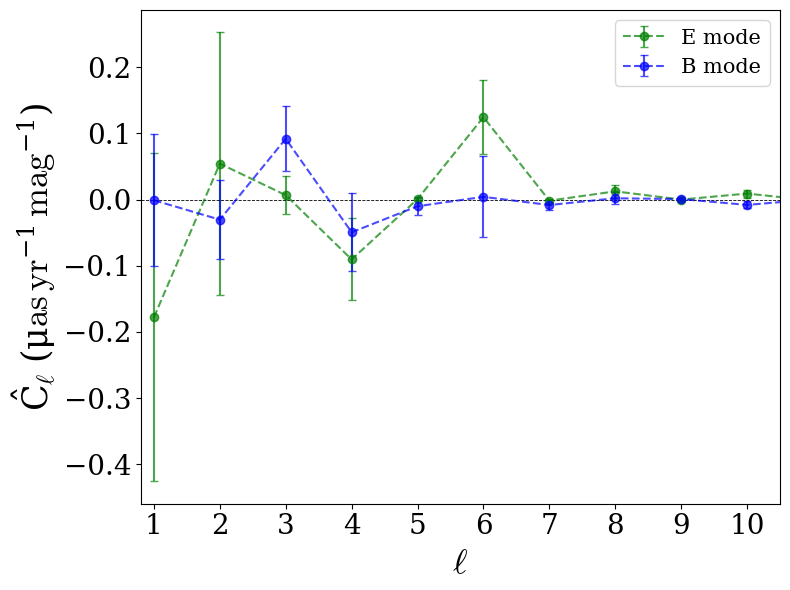

QSO PM x m10:
  E mode: chi2/dof = 12.02/10  p = 0.2839  (1.07 sigma)
  B mode: chi2/dof = 8.71/10  p = 0.5595  (0.58 sigma)


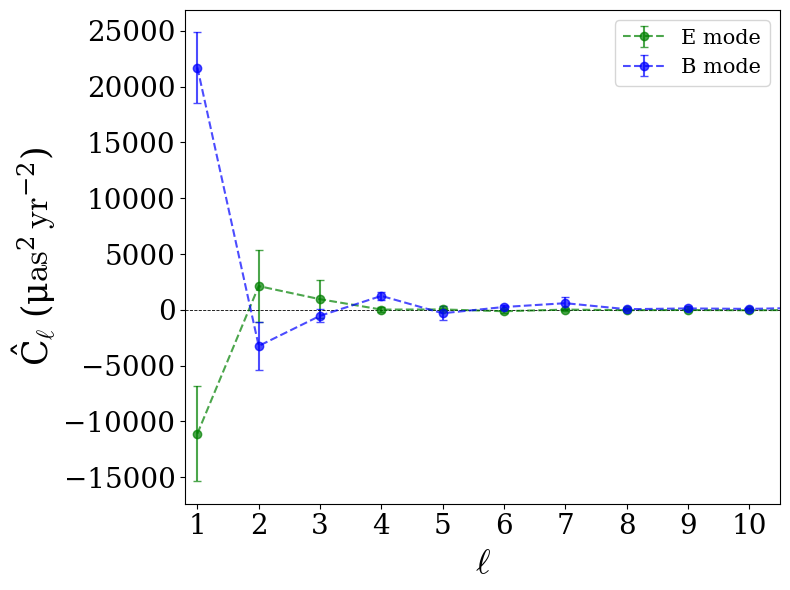

QSO PM x stellar PM:
  E mode: chi2/dof = 9.23/10  p = 0.5107  (0.66 sigma)
  B mode: chi2/dof = 71.16/10  p = 0.0000  (6.67 sigma)


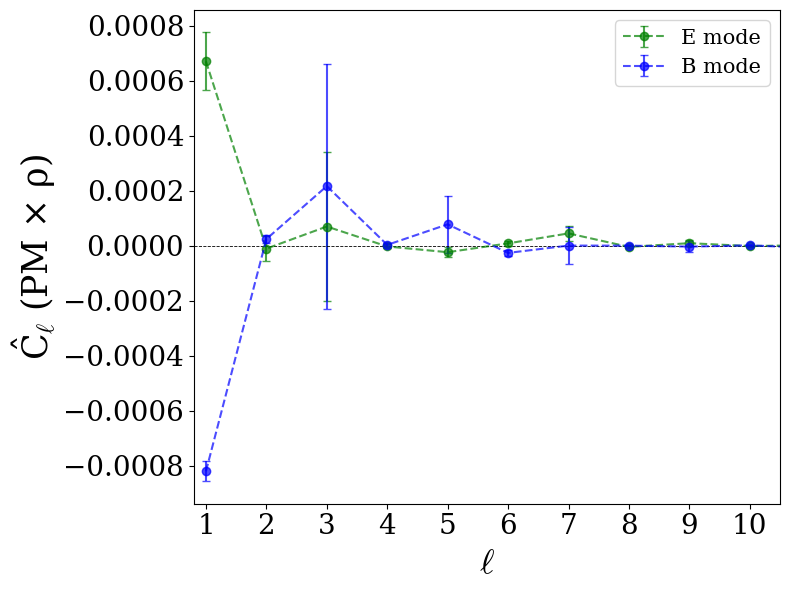

QSO PM x pm_corr:
  E mode: chi2/dof = 51.06/10  p = 0.0000  (5.23 sigma)
  B mode: chi2/dof = 519.28/10  p = 0.0000  (inf sigma)


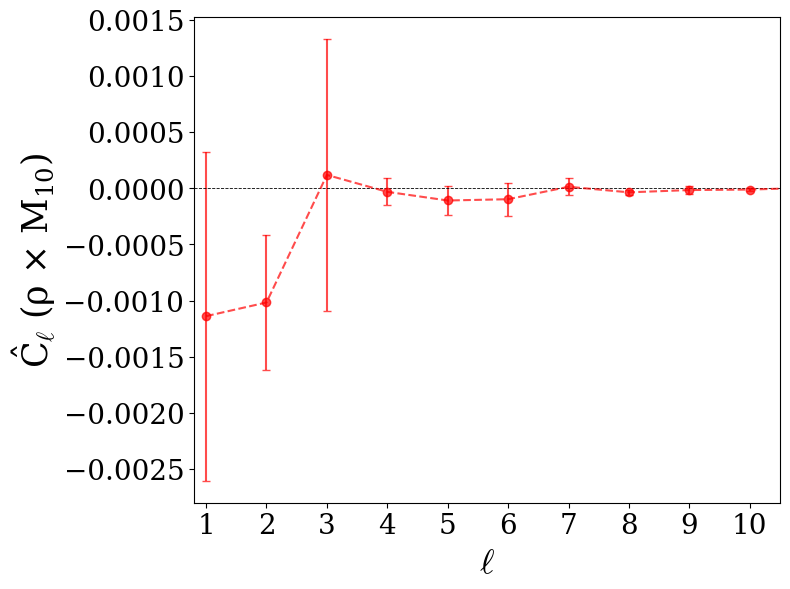

pm_corr x m10:
  TT: chi2/dof = 9.31/10  p = 0.5028  (0.67 sigma)


In [26]:
from scipy import stats as _stats
from scipy.special import erfinv as _erfinv

ell_mask_d1 = (ells_d1 >= 1) & (ells_d1 <= lmax_nmt)

def plot_d1(CL_E, CL_B, ERR_E, ERR_B, ylabel, fname):
    plt.figure(figsize=(8, 6))
    plt.errorbar(ells_d1[ell_mask_d1], CL_E[ell_mask_d1], yerr=ERR_E[ell_mask_d1],
                 fmt='go--', capsize=3, label='E mode', alpha=0.7)
    plt.errorbar(ells_d1[ell_mask_d1], CL_B[ell_mask_d1], yerr=ERR_B[ell_mask_d1],
                 fmt='bo--', capsize=3, label='B mode', alpha=0.7)
    plt.axhline(0, color='k', linewidth=0.6, linestyle='--')
    plt.xlabel(r'$\rm \ell$', fontsize=25)
    plt.ylabel(ylabel, fontsize=25)
    plt.legend(fontsize=15)
    plt.xlim(0.8, 10.5)
    plt.xticks(np.arange(1, 11, 1), fontsize=20)
    plt.yticks(fontsize=20)
    plt.tight_layout()
    #plt.savefig(f'output/{fname}_{dataset}.pdf')
    plt.show()

def significance_d1(CL, ERR, label):
    mask10 = (ells_d1 >= 1) & (ells_d1 <= 10)
    chi2 = np.sum((CL[mask10] / ERR[mask10])**2)
    dof  = mask10.sum()
    p    = _stats.chi2.sf(chi2, dof)
    nsig = np.sqrt(2) * _erfinv(1 - p)
    print(f'  {label}: chi2/dof = {chi2:.2f}/{dof}  p = {p:.4f}  ({nsig:.2f} sigma)')

# ── Plot 1: Auto QSO PM ───────────────────────────────────────────────────────
plot_d1(CL_d1_auto_EE * 1e6, CL_d1_auto_BB * 1e6,
        ERR_d1_auto_EE * 1e6, ERR_d1_auto_BB * 1e6,
        r'$\hat{C}_{\rm  \ell} \, \, (\mu\mathrm{as}^2\,\mathrm{yr}^{-2})$',
        'cl_d1_qpm_auto')
print('Auto QSO PM x QSO PM:')
significance_d1(CL_d1_auto_EE, ERR_d1_auto_EE, 'E mode')
significance_d1(CL_d1_auto_BB, ERR_d1_auto_BB, 'B mode')

# ── Plot 2: Cross QSO PM x stellar density ────────────────────────────────────
plot_d1(CL_d1_sdens_E * 1e3, CL_d1_sdens_B * 1e3,
        ERR_d1_sdens_E * 1e3, ERR_d1_sdens_B * 1e3,
        r'$\hat{C}_{\rm  \ell} \, \,(\mu\mathrm{as}\,\mathrm{yr}^{-1} \, \mathrm{count}^{-1} \, \mathrm{pix})$',
        'cl_d1_qpm_x_sdens')
print('QSO PM x stellar density:')
significance_d1(CL_d1_sdens_E, ERR_d1_sdens_E, 'E mode')
significance_d1(CL_d1_sdens_B, ERR_d1_sdens_B, 'B mode')

# ── Plot 3: Cross QSO PM x m10 ────────────────────────────────────────────────
plot_d1(CL_d1_m10_E * 1e3, CL_d1_m10_B * 1e3,
        ERR_d1_m10_E * 1e3, ERR_d1_m10_B * 1e3,
        r'$\hat{C}_{\rm  \ell} \, \, (\mu\mathrm{as}\,\mathrm{yr}^{-1}\,\mathrm{mag}^{-1})$',
        'cl_d1_qpm_x_m10')
print('QSO PM x m10:')
significance_d1(CL_d1_m10_E, ERR_d1_m10_E, 'E mode')
significance_d1(CL_d1_m10_B, ERR_d1_m10_B, 'B mode')

# ── Plot 4: Cross QSO PM x stellar PM ────────────────────────────────────────
plot_d1(CL_d1_spm_EE * 1e6, CL_d1_spm_BB * 1e6,
        ERR_d1_spm_EE * 1e6, ERR_d1_spm_BB * 1e6,
        r'$\hat{C}_{\rm  \ell} \, \, (\mu\mathrm{as}^2\,\mathrm{yr}^{-2})$',
        'cl_d1_qpm_x_spm')
print('QSO PM x stellar PM:')
significance_d1(CL_d1_spm_EE, ERR_d1_spm_EE, 'E mode')
significance_d1(CL_d1_spm_BB, ERR_d1_spm_BB, 'B mode')

# ── Plot 5: Cross QSO PM x pm_corr ───────────────────────────────────────────
plot_d1(CL_d1_pmcorr_E, CL_d1_pmcorr_B,
        ERR_d1_pmcorr_E, ERR_d1_pmcorr_B,
        r'$\hat{C}_{\rm  \ell}$ (PM $\times$ $\rho$)',
        'cl_d1_qpm_x_corr')
print('QSO PM x pm_corr:')
significance_d1(CL_d1_pmcorr_E, ERR_d1_pmcorr_E, 'E mode')
significance_d1(CL_d1_pmcorr_B, ERR_d1_pmcorr_B, 'B mode')

# ── Plot 6: Cross pm_corr x m10  (spin-0 x spin-0, scalar) ───────────────────
def plot_d1_scalar(CL, ERR, ylabel, fname):
    plt.figure(figsize=(8, 6))
    plt.errorbar(ells_d1[ell_mask_d1], CL[ell_mask_d1], yerr=ERR[ell_mask_d1],
                 fmt='ro--', capsize=3, alpha=0.7)
    plt.axhline(0, color='k', linewidth=0.6, linestyle='--')
    plt.xlabel(r'$\rm \ell$', fontsize=25)
    plt.ylabel(ylabel, fontsize=25)
    plt.xlim(0.8, 10.5)
    plt.xticks(np.arange(1, 11, 1), fontsize=20)
    plt.yticks(fontsize=20)
    plt.tight_layout()
    #plt.savefig(f'output/{fname}_{dataset}.pdf')
    plt.show()

def significance_d1_scalar(CL, ERR, label):
    mask10 = (ells_d1 >= 1) & (ells_d1 <= 10)
    chi2 = np.sum((CL[mask10] / ERR[mask10])**2)
    dof  = mask10.sum()
    p    = _stats.chi2.sf(chi2, dof)
    nsig = np.sqrt(2) * _erfinv(1 - p)
    print(f'  {label}: chi2/dof = {chi2:.2f}/{dof}  p = {p:.4f}  ({nsig:.2f} sigma)')

plot_d1_scalar(CL_d1_corrm10, ERR_d1_corrm10,
               r'$\hat{C}_{\rm  \ell}$ ($\rho$ $\times$ $M_{10}$)',
               'cl_d1_corr_x_m10')
print('pm_corr x m10:')
significance_d1_scalar(CL_d1_corrm10, ERR_d1_corrm10, 'TT')


## 6×3 panel: all cross-spectra across all 6 datasets

Rows: Gaia | Gaia |b|>20° | Gaia |b|>30° | Quaia | Quaia |b|>20° | Quaia |b|>30°  
Columns: QSO PM × stellar density | QSO PM × stellar PM | QSO PM × M10

In [27]:
#  3×6 panel: all cross-spectra across all 6 datasets

# Datasets: (label, galactic_cut_deg, use_quaia_filter)
DATASETS = [
    ('gaia',             0,   False),
    ('gaia_galcut_20',   20,  False),
    ('gaia_galcut_30',   30,  False),
    ('quaia',            0,   True),
    ('quaia_galcut_20',  20,  True),
    ('quaia_galcut_30',  30,  True),
]

panel_results = {}   # label -> dict of CL/ERR arrays

for (label, galcut, use_quaia) in DATASETS:
    print(f'\n── {label} (galcut={galcut}°, quaia={use_quaia}) ──')

    # 1. Galactic mask for this dataset
    # galactic cut handled inside compute_pixel_stats

    # 2. QSO catalog for this dataset
    if use_quaia:
        gaia_ds = quaia
    else:
        gaia_ds = gaia

    # 3. Rebuild QSO PM weighted-mean maps (full 2x2 covariance weighting)
    pix_data_ds = compute_pixel_stats(
        gaia_ds['ra'].values, gaia_ds['dec'].values,
        gaia_ds['pmra'].values, gaia_ds['pmdec'].values,
        gaia_ds['pmra_error'].values, gaia_ds['pmdec_error'].values,
        gaia_ds['pmra_pmdec_corr'].values,
        nside=nside, galcut=galcut,
    )
    pmra_wm_ds  = pix_data_ds['pmra_wm']
    pmdec_wm_ds = pix_data_ds['pmdec_wm']

    # 4. Masks
    mask_gaia_ds  = pix_data_ds['mask']  # includes galactic cut + validity
    mask_cross_ds = mask_gaia_ds & mask_sdens & mask_m10
    mask_all_ds   = (mask_gaia_ds & mask_star_pm & mask_cross_ds).astype(float)
    apod_all_ds   = nmt.mask_apodization(mask_all_ds, APOD_SCALE, APOD_TYPE)  # for auto-spectrum
    print(f'   f_sky = {mask_all_ds.mean():.3f}')

    # 5. Mean-subtract scalar maps within new mask
    sum_mask      = np.sum(mask_cross_ds)
    mean_sdens_ds = np.sum(nstar_per_pixel * mask_cross_ds) / sum_mask
    mean_m10_ds   = np.sum(m10_map         * mask_cross_ds) / sum_mask
    nstar_ms_ds   = np.where(mask_cross_ds, nstar_per_pixel - mean_sdens_ds, 0.0)
    m10_ms_ds     = np.where(mask_cross_ds, m10_map         - mean_m10_ds,   0.0)

    # 6. NaMaster fields
    # apodized field for auto-spectrum (reduces mode-coupling inversion artifacts)
    f_qpm_apod_ds = nmt.NmtField(apod_all_ds, [-pmdec_wm_ds, pmra_wm_ds], spin=1)
    # binary-mask fields for cross-spectra (unchanged)
    f_qpm_ds   = nmt.NmtField(mask_all_ds, [-pmdec_wm_ds,   pmra_wm_ds],   spin=1)
    f_sdens_ds = nmt.NmtField(mask_all_ds, [nstar_ms_ds])
    f_m10_ds   = nmt.NmtField(mask_all_ds, [m10_ms_ds])
    f_spm_ds   = nmt.NmtField(mask_all_ds, [-star_pmdec_wm, star_pmra_wm], spin=1)

    # 7. Workspaces + auto-spectra for fiducials
    print('   Computing coupling matrices...')
    ws_auto_ds     = nmt.NmtWorkspace(); ws_auto_ds.compute_coupling_matrix(f_qpm_apod_ds, f_qpm_apod_ds, bins_d1)
    ws_sdens_ds    = nmt.NmtWorkspace(); ws_sdens_ds.compute_coupling_matrix(f_qpm_ds, f_sdens_ds, bins_d1)
    ws_m10_ds      = nmt.NmtWorkspace(); ws_m10_ds.compute_coupling_matrix(f_qpm_ds,   f_m10_ds,   bins_d1)
    ws_spm_ds      = nmt.NmtWorkspace(); ws_spm_ds.compute_coupling_matrix(f_qpm_ds,   f_spm_ds,   bins_d1)
    ws_spm_auto_ds = nmt.NmtWorkspace(); ws_spm_auto_ds.compute_coupling_matrix(f_spm_ds, f_spm_ds, bins_d1)

    def dc_ds(ws, f1, f2):
        return ws.decouple_cell(nmt.compute_coupled_cell(f1, f2))

    # 8. Data Cl
    cl_auto_ds     = dc_ds(ws_auto_ds,     f_qpm_apod_ds, f_qpm_apod_ds)  # apodized auto
    cl_sdens_ds    = dc_ds(ws_sdens_ds,    f_qpm_ds, f_sdens_ds)
    cl_m10_ds      = dc_ds(ws_m10_ds,      f_qpm_ds, f_m10_ds)
    cl_spm_ds      = dc_ds(ws_spm_ds,      f_qpm_ds, f_spm_ds)
    cl_spm_auto_ds = dc_ds(ws_spm_auto_ds, f_spm_ds, f_spm_ds)

    # 9. Fiducials for MC (use ells_d1[1:] to skip ell=0 placeholder)
    fid_qpm_EE_ds = bandpower_to_full_cl(ells_d1[1:], np.maximum(cl_auto_ds[0][1:], 0), lmax_nmt)
    fid_qpm_BB_ds = bandpower_to_full_cl(ells_d1[1:], np.maximum(cl_auto_ds[3][1:], 0), lmax_nmt)
    fid_spm_EE_ds = bandpower_to_full_cl(ells_d1[1:], cl_spm_auto_ds[0][1:], lmax_nmt)
    fid_spm_BB_ds = bandpower_to_full_cl(ells_d1[1:], cl_spm_auto_ds[3][1:], lmax_nmt)
    fid_sdens_ds  = bandpower_to_full_cl(ells[ells <= lmax_nmt], cl_sdens_auto[ells <= lmax_nmt], lmax_nmt)
    fid_m10_ds    = bandpower_to_full_cl(ells[ells <= lmax_nmt], cl_m10_auto  [ells <= lmax_nmt], lmax_nmt)

    # 10. MC simulations for error bars
    n_ells_d1       = len(ells_d1)
    sims_sdens_E_ds = np.zeros((N_SIMS, n_ells_d1))
    sims_sdens_B_ds = np.zeros((N_SIMS, n_ells_d1))
    sims_m10_E_ds   = np.zeros((N_SIMS, n_ells_d1))
    sims_m10_B_ds   = np.zeros((N_SIMS, n_ells_d1))
    sims_spm_EE_ds  = np.zeros((N_SIMS, n_ells_d1))
    sims_spm_BB_ds  = np.zeros((N_SIMS, n_ells_d1))
    sims_auto_EE_ds = np.zeros((N_SIMS, n_ells_d1))
    sims_auto_BB_ds = np.zeros((N_SIMS, n_ells_d1))

    print(f'   Running {N_SIMS} MC sims...')
    for j in range(N_SIMS):
        # QSO PM (spin-1)
        alm_E_q = hp.synalm(fid_qpm_EE_ds, lmax=lmax_nmt)
        alm_B_q = hp.synalm(fid_qpm_BB_ds, lmax=lmax_nmt)
        mth_q, mph_q = hp.alm2map_spin([alm_E_q, alm_B_q], nside, spin=1, lmax=lmax_nmt)
        sim_pmra_q = mph_q;  sim_pmdec_q = -mth_q

        # Stellar PM (spin-1, independent)
        alm_E_s = hp.synalm(fid_spm_EE_ds, lmax=lmax_nmt)
        alm_B_s = hp.synalm(fid_spm_BB_ds, lmax=lmax_nmt)
        mth_s, mph_s = hp.alm2map_spin([alm_E_s, alm_B_s], nside, spin=1, lmax=lmax_nmt)
        sim_pmra_s = mph_s;  sim_pmdec_s = -mth_s

        # Scalar fields (mean-subtract within mask)
        sim_sd_raw   = hp.synfast(fid_sdens_ds, nside, lmax=lmax_nmt, verbose=False)
        sim_m10_raw  = hp.synfast(fid_m10_ds,   nside, lmax=lmax_nmt, verbose=False)
        sim_sd_ms    = sim_sd_raw  - np.sum(sim_sd_raw  * mask_all_ds) / np.sum(mask_all_ds)
        sim_m10_ms2  = sim_m10_raw - np.sum(sim_m10_raw * mask_all_ds) / np.sum(mask_all_ds)

        f_q_apod_j = nmt.NmtField(apod_all_ds, [-sim_pmdec_q, sim_pmra_q], spin=1)  # apodized: auto
        f_q_j   = nmt.NmtField(mask_all_ds, [-sim_pmdec_q, sim_pmra_q], spin=1)
        f_s_j   = nmt.NmtField(mask_all_ds, [-sim_pmdec_s, sim_pmra_s], spin=1)
        f_sd_j  = nmt.NmtField(mask_all_ds, [sim_sd_ms])
        f_m10_j = nmt.NmtField(mask_all_ds, [sim_m10_ms2])

        cl_sd_j   = ws_sdens_ds.decouple_cell(nmt.compute_coupled_cell(f_q_j,      f_sd_j))
        cl_m10_j  = ws_m10_ds.decouple_cell(nmt.compute_coupled_cell(f_q_j,        f_m10_j))
        cl_spm_j  = ws_spm_ds.decouple_cell(nmt.compute_coupled_cell(f_q_j,        f_s_j))
        cl_auto_j = ws_auto_ds.decouple_cell(nmt.compute_coupled_cell(f_q_apod_j,  f_q_apod_j))

        sims_sdens_E_ds[j] = cl_sd_j[0];  sims_sdens_B_ds[j] = cl_sd_j[1]
        sims_m10_E_ds[j]   = cl_m10_j[0]; sims_m10_B_ds[j]   = cl_m10_j[1]
        sims_spm_EE_ds[j]  = cl_spm_j[0]; sims_spm_BB_ds[j]  = cl_spm_j[3]
        sims_auto_EE_ds[j] = cl_auto_j[0]; sims_auto_BB_ds[j] = cl_auto_j[3]

        if (j + 1) % 100 == 0:
            print(f'     {j+1}/{N_SIMS}')

    panel_results[label] = {
        'CL_sdens_E':  cl_sdens_ds[0],  'CL_sdens_B':  cl_sdens_ds[1],
        'ERR_sdens_E': np.std(sims_sdens_E_ds, axis=0),
        'ERR_sdens_B': np.std(sims_sdens_B_ds, axis=0),
        'CL_m10_E':    cl_m10_ds[0],    'CL_m10_B':    cl_m10_ds[1],
        'ERR_m10_E':   np.std(sims_m10_E_ds, axis=0),
        'ERR_m10_B':   np.std(sims_m10_B_ds, axis=0),
        'CL_spm_EE':   cl_spm_ds[0],    'CL_spm_BB':   cl_spm_ds[3],
        'ERR_spm_EE':  np.std(sims_spm_EE_ds, axis=0),
        'ERR_spm_BB':  np.std(sims_spm_BB_ds, axis=0),
        'CL_auto_EE':  cl_auto_ds[0],   'CL_auto_BB':  cl_auto_ds[3],
        'ERR_auto_EE': np.std(sims_auto_EE_ds, axis=0),
        'ERR_auto_BB': np.std(sims_auto_BB_ds, axis=0),
    }
    print(f'   {label} done.')

print('\nAll datasets complete.')




── gaia (galcut=0°, quaia=False) ──
   f_sky = 0.879
   Computing coupling matrices...
   Running 500 MC sims...


/tmp/ipykernel_624013/3038485929.py:113: HealpyDeprecationWarning: "verbose" was deprecated in version 1.15.0 and will be removed in a future version. 
  sim_sd_raw   = hp.synfast(fid_sdens_ds, nside, lmax=lmax_nmt, verbose=False)
/tmp/ipykernel_624013/3038485929.py:114: HealpyDeprecationWarning: "verbose" was deprecated in version 1.15.0 and will be removed in a future version. 
  sim_m10_raw  = hp.synfast(fid_m10_ds,   nside, lmax=lmax_nmt, verbose=False)


     100/500
     200/500
     300/500
     400/500
     500/500
   gaia done.

── gaia_galcut_20 (galcut=20°, quaia=False) ──
   f_sky = 0.658
   Computing coupling matrices...
   Running 500 MC sims...
     100/500
     200/500
     300/500
     400/500
     500/500
   gaia_galcut_20 done.

── gaia_galcut_30 (galcut=30°, quaia=False) ──
   f_sky = 0.500
   Computing coupling matrices...
   Running 500 MC sims...
     100/500
     200/500
     300/500
     400/500
     500/500
   gaia_galcut_30 done.

── quaia (galcut=0°, quaia=True) ──
   f_sky = 0.842
   Computing coupling matrices...
   Running 500 MC sims...
     100/500
     200/500
     300/500
     400/500
     500/500
   quaia done.

── quaia_galcut_20 (galcut=20°, quaia=True) ──
   f_sky = 0.657
   Computing coupling matrices...
   Running 500 MC sims...
     100/500
     200/500
     300/500
     400/500
     500/500
   quaia_galcut_20 done.

── quaia_galcut_30 (galcut=30°, quaia=True) ──
   f_sky = 0.500
   Computing coupli

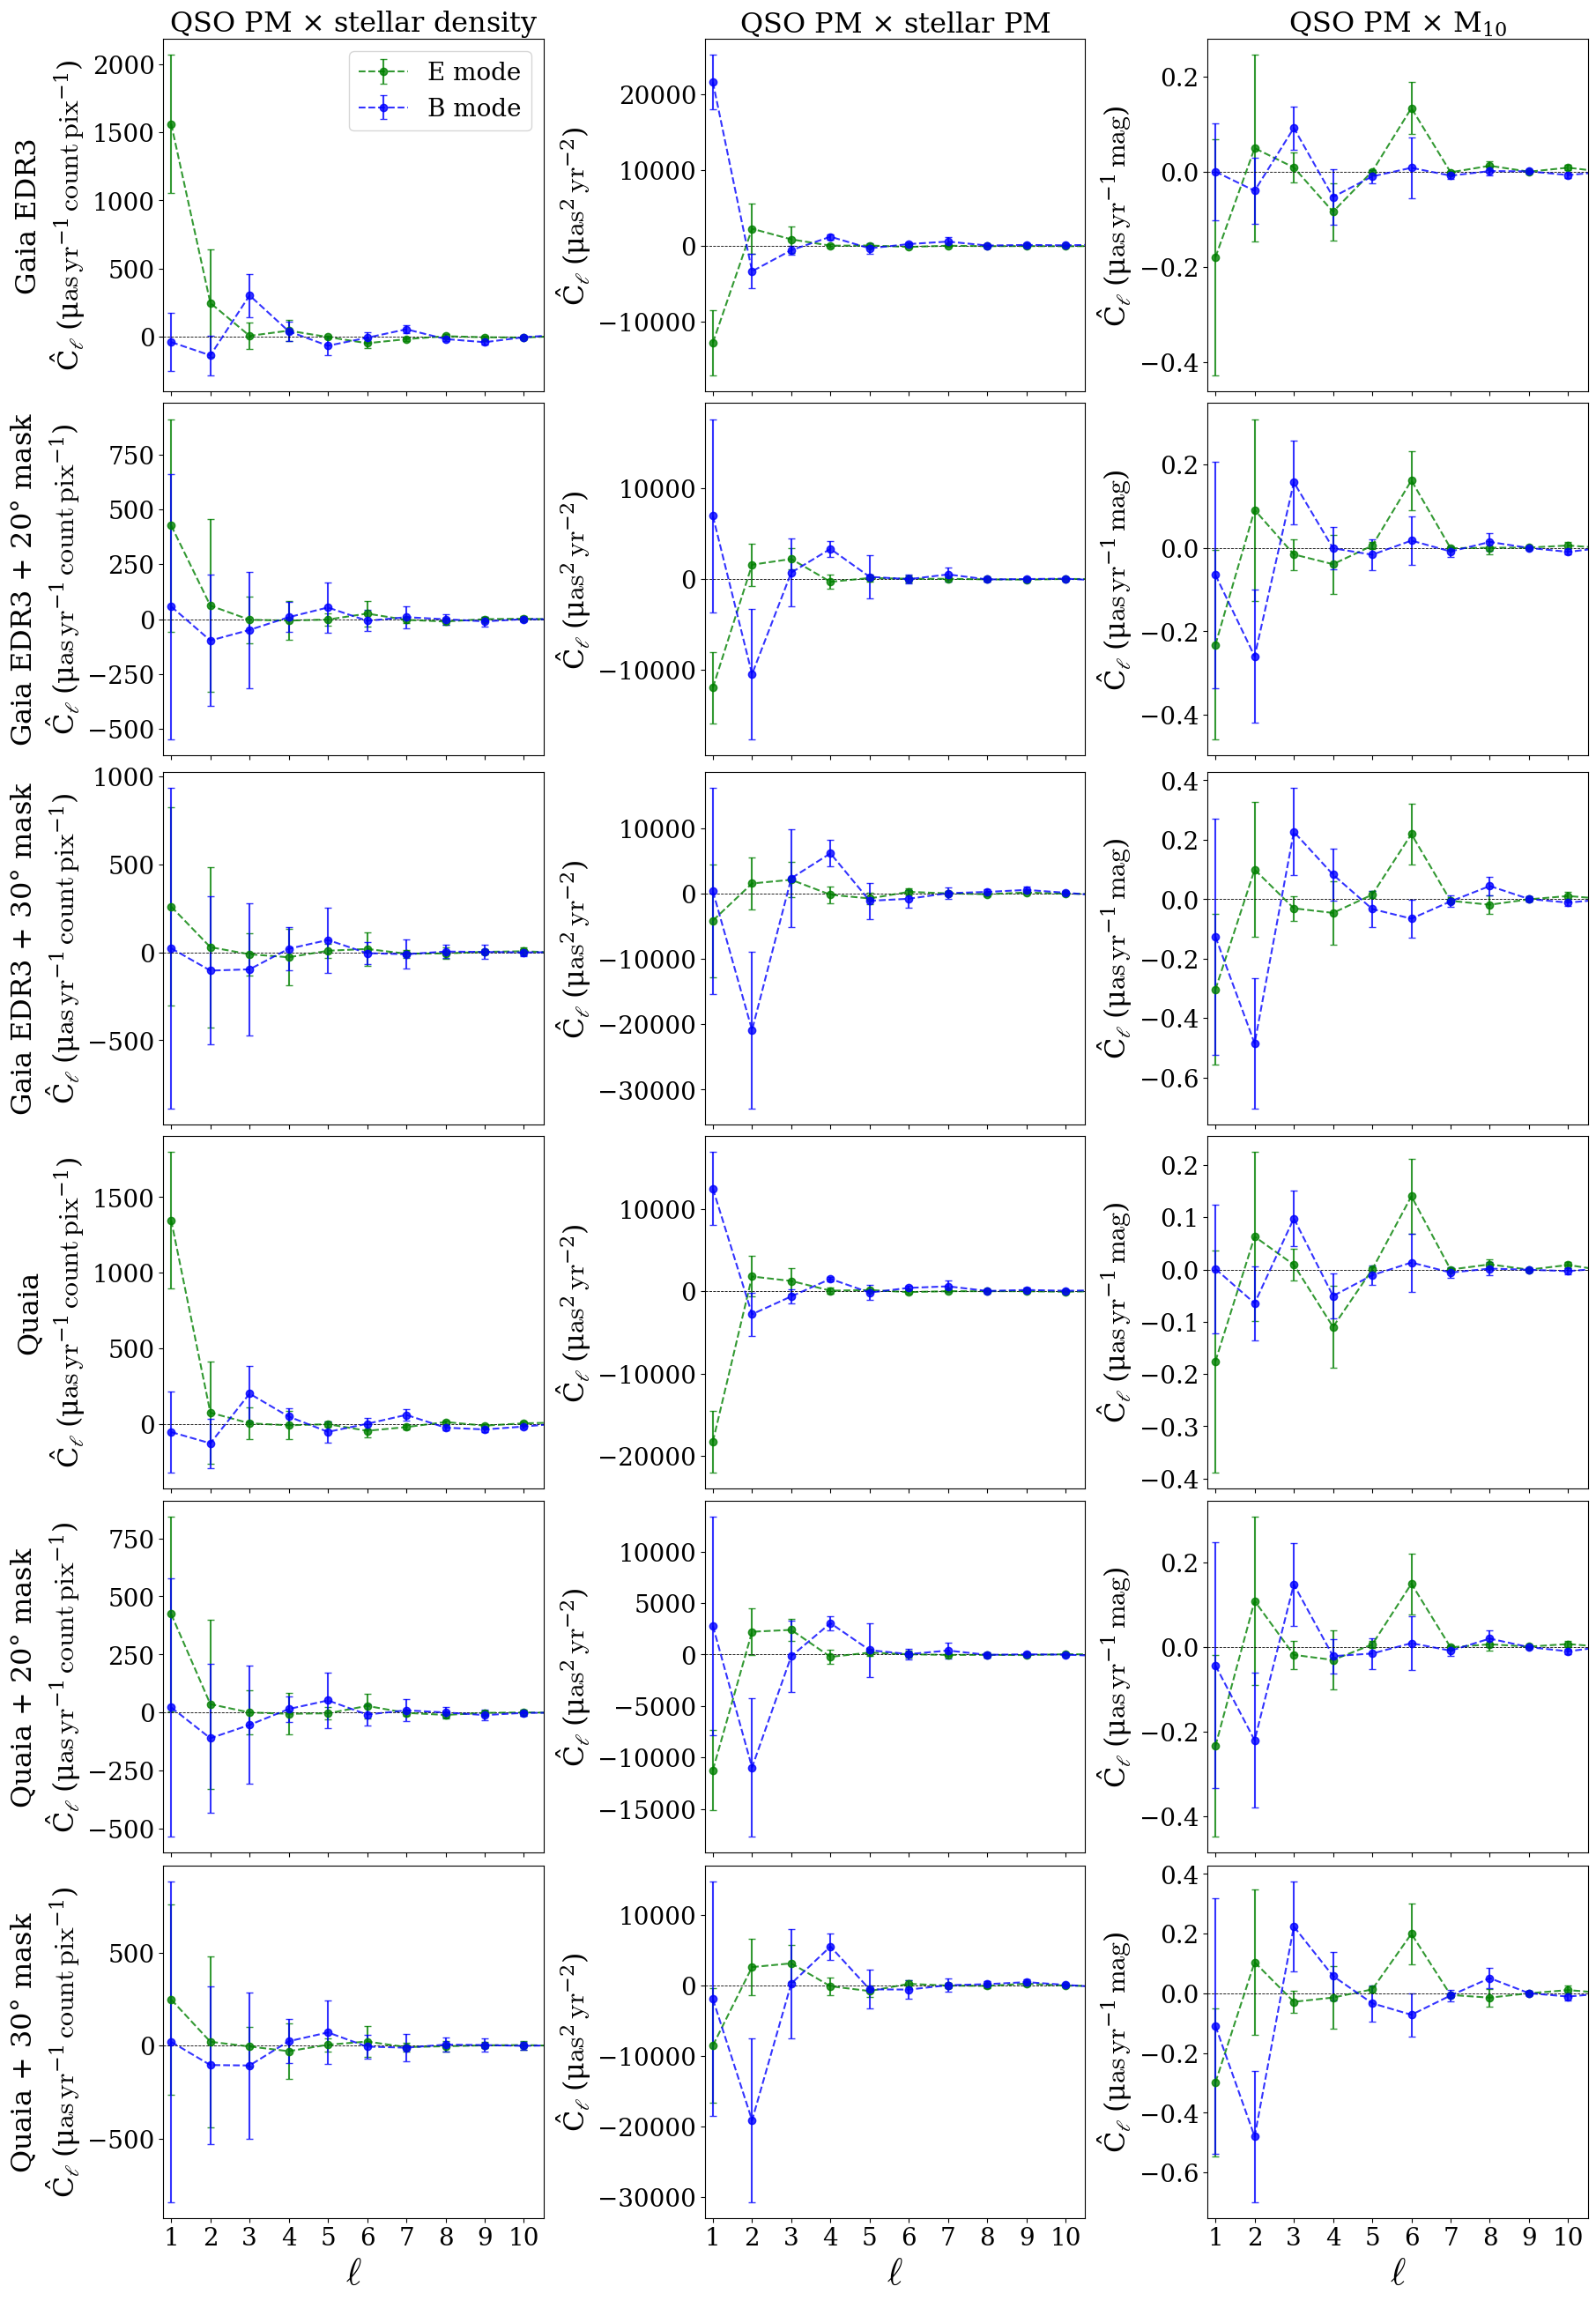

Saved output/cross_spectra_panel.pdf


In [28]:
# ── 6×3 Panel plot ────────────────────────────────────────────────────────────
# Rows: 6 data configurations | Columns: 3 systematics templates
row_labels = [
    'Gaia EDR3',
    r'Gaia EDR3 + $20°$ mask',
    r'Gaia EDR3 + $30°$ mask',
    'Quaia',
    r'Quaia + $20°$ mask',
    r'Quaia + $30°$ mask',
]
col_specs = [
    # (key_prefix, col_title, ylabel, scale)
    ('sdens', r'QSO PM $\times$ stellar density',
     r'$\hat{C}_\ell \;(\mu\mathrm{as}\,\mathrm{yr}^{-1}\,\mathrm{count}\,\mathrm{pix}^{-1})$', 1e3),
    ('spm',   r'QSO PM $\times$ stellar PM',
     r'$\hat{C}_\ell \;(\mu\mathrm{as}^2\,\mathrm{yr}^{-2})$',                                      1e6),
    ('m10',   r'QSO PM $\times$ $M_{10}$',
     r'$\hat{C}_\ell \;(\mu\mathrm{as}\,\mathrm{yr}^{-1}\,\mathrm{mag})$',                        1e3),
]
ds_order = ['gaia', 'gaia_galcut_20', 'gaia_galcut_30',
            'quaia', 'quaia_galcut_20', 'quaia_galcut_30']

fig, axes = plt.subplots(6, 3, figsize=(18, 26), constrained_layout=True, sharex=True)

for row, (lbl, row_label) in enumerate(zip(ds_order, row_labels)):
    for col, (key, col_title, ylabel, scale) in enumerate(col_specs):
        ax = axes[row, col]
        r  = panel_results[lbl]

        if key == 'spm':
            CL_E  = r['CL_spm_EE'];  CL_B  = r['CL_spm_BB']
            ERR_E = r['ERR_spm_EE']; ERR_B = r['ERR_spm_BB']
            e_lab, b_lab = 'EE', 'BB'
        else:
            CL_E  = r[f'CL_{key}_E'];  CL_B  = r[f'CL_{key}_B']
            ERR_E = r[f'ERR_{key}_E']; ERR_B = r[f'ERR_{key}_B']
            e_lab, b_lab = 'E mode', 'B mode'

        ax.errorbar(ells_d1[ell_mask_d1],
                    CL_E[ell_mask_d1] * scale,
                    yerr=ERR_E[ell_mask_d1] * scale,
                    fmt='go--', capsize=3, label=e_lab, alpha=0.8)
        ax.errorbar(ells_d1[ell_mask_d1],
                    CL_B[ell_mask_d1] * scale,
                    yerr=ERR_B[ell_mask_d1] * scale,
                    fmt='bo--', capsize=3, label=b_lab, alpha=0.8)
        ax.axhline(0, color='k', linewidth=0.6, linestyle='--')
        ax.set_xlim(0.8, 10.5)
        ax.set_xticks(range(1, 11))
        ax.tick_params(labelsize=20)

        if row == 0:
            ax.set_title(col_title, fontsize=23)
        if col == 0:
            ax.set_ylabel(row_label + '\n' + ylabel, fontsize=23)
        else:
            ax.set_ylabel(ylabel, fontsize=23)
        if row == 5:
            ax.set_xlabel(r'$\rm \ell$', fontsize=30)
        if row == 0 and col == 0:
            ax.legend(fontsize=20)

import os
os.makedirs('output', exist_ok=True)
plt.savefig('output/cross_spectra_panel.pdf', bbox_inches='tight')
plt.show()
print('Saved output/cross_spectra_panel.pdf')


In [29]:
# ── Diagnostic: MASTER cross-ell contributions to dipole BB ──────────────────
# Set DIAG_GALCUT and DIAG_QUAIA to check any dataset
DIAG_GALCUT = 20
DIAG_QUAIA  = False   # True = Quaia, False = Gaia

gaia_diag = quaia if DIAG_QUAIA else gaia
pix_diag  = compute_pixel_stats(
    gaia_diag['ra'].values, gaia_diag['dec'].values,
    gaia_diag['pmra'].values, gaia_diag['pmdec'].values,
    gaia_diag['pmra_error'].values, gaia_diag['pmdec_error'].values,
    gaia_diag['pmra_pmdec_corr'].values,
    nside=nside, galcut=DIAG_GALCUT,
)
mask_diag  = (pix_diag['mask'] & mask_star_pm & mask_sdens & mask_m10).astype(float)
apod_diag  = nmt.mask_apodization(mask_diag, APOD_SCALE, APOD_TYPE)
f_diag     = nmt.NmtField(apod_diag, [-pix_diag['pmdec_wm'], pix_diag['pmra_wm']], spin=1)
ws_diag    = nmt.NmtWorkspace()
ws_diag.compute_coupling_matrix(f_diag, f_diag, bins_d1)

print(f'galcut={DIAG_GALCUT}° quaia={DIAG_QUAIA}  f_sky={mask_diag.mean():.3f}')

# Coupled cell and decoupled auto-spectrum
cl_coup = nmt.compute_coupled_cell(f_diag, f_diag)
cl_dec  = ws_diag.decouple_cell(cl_coup)
print(f'decoupled BB dipole: {cl_dec[3][0]*1e6:.4f} uas^2/yr^2')
print(f'decoupled EE dipole: {cl_dec[0][0]*1e6:.4f} uas^2/yr^2')

# SVD of M
M_diag = ws_diag.get_coupling_matrix()
sv = np.linalg.svd(M_diag, compute_uv=False)
print(f'\nM singular values: max={sv.max():.3e}  min={sv.min():.3e}  zeros={(sv<1e-10).sum()}')
print(f'effective cond: {sv.max()/sv[sv>1e-10].min():.3e}')

# Pseudo-inverse
M_pinv = np.linalg.pinv(M_diag)
n_bins_int = M_diag.shape[0] // 4
M_pinv_r = M_pinv.reshape(4, n_bins_int, 4, n_bins_int)

# Full breakdown: what contributes to decoupled BB dipole (output bin 0)
dip = 1  # internal index for ell=1 (ell=0 is at index 0)
labels = ['EE', 'EB', 'BE', 'BB']
print(f'\n=== Full cross-ell contribution to decoupled BB dipole ===')
total = 0.0
for j, lbl in enumerate(labels):
    contrib = np.sum(M_pinv_r[3, dip, j, :] * cl_coup[j])
    print(f'  {lbl} → BB dipole: {contrib*1e6:+.4f} uas^2/yr^2')
    total += contrib
print(f'  TOTAL (should match decoupled BB[0]): {total*1e6:.4f} uas^2/yr^2')


galcut=20° quaia=False  f_sky=0.658
decoupled BB dipole: 3.5578 uas^2/yr^2
decoupled EE dipole: 82.6808 uas^2/yr^2

M singular values: max=6.562e-01  min=0.000e+00  zeros=4
effective cond: 1.668e+00

=== Full cross-ell contribution to decoupled BB dipole ===
  EE → BB dipole: -0.0000 uas^2/yr^2
  EB → BB dipole: -0.0003 uas^2/yr^2
  BE → BB dipole: -0.0189 uas^2/yr^2
  BB → BB dipole: +15.4847 uas^2/yr^2
  TOTAL (should match decoupled BB[0]): 15.4655 uas^2/yr^2


In [30]:
# #  Stellar PM auto-spectrum: 1×3 panel (galcut = 0°, 20°, 30°) 
# GALCUTS      = [0, 20, 30]
# _labels      = [r'galcut = 0°', r'galcut = 20°', r'galcut = 30°']
# N_SIMS_AUTO  = 200

# spm_auto_EE_list    = []
# spm_auto_BB_list    = []
# spm_auto_ERR_EE_list = []
# spm_auto_ERR_BB_list = []

# for galcut in GALCUTS:
#     mask_gal_ds  = np.abs(galactic_coords.b.deg) > galcut
#     mask_gaia_ds = (gaia_pmra_wm != 0) & (gaia_pmdec_wm != 0) & mask_gal_ds
#     mask_all_ds  = (mask_gaia_ds & mask_star_pm & mask_sdens & mask_m10).astype(float)
#     print(f'galcut={galcut}°  f_sky={mask_all_ds.mean():.3f}')

#     # Data Cl
#     f_spm_ds = nmt.NmtField(mask_all_ds, [-star_pmdec_wm, star_pmra_wm], spin=1)
#     ws_tmp   = nmt.NmtWorkspace()
#     ws_tmp.compute_coupling_matrix(f_spm_ds, f_spm_ds, bins_d1)
#     cl_tmp   = ws_tmp.decouple_cell(nmt.compute_coupled_cell(f_spm_ds, f_spm_ds))
#     spm_auto_EE_list.append(cl_tmp[0])
#     spm_auto_BB_list.append(cl_tmp[3])

#     # Fiducials (clip to non-negative for hp.synalm)
#     fid_EE = bandpower_to_full_cl(ells_d1[1:], np.maximum(cl_tmp[0][1:], 0), lmax_nmt)
#     fid_BB = bandpower_to_full_cl(ells_d1[1:], np.maximum(cl_tmp[3][1:], 0), lmax_nmt)

#     # MC sims
#     n_ells  = len(ells_d1)
#     sims_EE = np.zeros((N_SIMS_AUTO, n_ells))
#     sims_BB = np.zeros((N_SIMS_AUTO, n_ells))
#     for j in range(N_SIMS_AUTO):
#         alm_E  = hp.synalm(fid_EE, lmax=lmax_nmt)
#         alm_B  = hp.synalm(fid_BB, lmax=lmax_nmt)
#         mth, mph = hp.alm2map_spin([alm_E, alm_B], nside, spin=1, lmax=lmax_nmt)
#         f_sim  = nmt.NmtField(mask_all_ds, [-mth, mph], spin=1)
#         cl_sim = ws_tmp.decouple_cell(nmt.compute_coupled_cell(f_sim, f_sim))
#         sims_EE[j] = cl_sim[0]
#         sims_BB[j] = cl_sim[3]
#         if (j + 1) % 50 == 0:
#             print(f'  {j+1}/{N_SIMS_AUTO}')

#     spm_auto_ERR_EE_list.append(np.std(sims_EE, axis=0))
#     spm_auto_ERR_BB_list.append(np.std(sims_BB, axis=0))
#     print(f'  done.')

# #  Plot 
# import matplotlib.ticker as ticker

# def sci_fmt(x, pos):
#     if x == 0:
#         return '0'
#     exp = int(np.floor(np.log10(abs(x))))
#     coef = x / 10**exp
#     return rf'${coef:.1f}\times10^{{{exp}}}$'

# ell_mask = (ells_d1 >= 1) & (ells_d1 <= 10)
# ell_plot = ells_d1[ell_mask]
# ylabel   = r'$\hat{C}_{\rm  \ell} \, \, (\mu\mathrm{as}^2\,\mathrm{yr}^{-2})$'

# fig, axes = plt.subplots(1, 3, figsize=(24, 6), sharey=True)

# for i, (ax, label, EE, BB, ERR_EE, ERR_BB) in enumerate(zip(
#         axes, _labels,
#         spm_auto_EE_list, spm_auto_BB_list,
#         spm_auto_ERR_EE_list, spm_auto_ERR_BB_list)):
#     ax.errorbar(ell_plot, EE[ell_mask] * 1e6, yerr=ERR_EE[ell_mask] * 1e6,
#                 fmt='go--', capsize=3, label='E mode', alpha=0.7)
#     ax.errorbar(ell_plot, BB[ell_mask] * 1e6, yerr=ERR_BB[ell_mask] * 1e6,
#                 fmt='bo--', capsize=3, label='B mode', alpha=0.7)
#     ax.axhline(0, color='k', linewidth=0.6, linestyle='--')
#     ax.set_xlabel(r'$\rm \ell$', fontsize=25)
#     ax.set_title(f'Stellar PM auto — {label}', fontsize=16)
#     ax.set_xlim(0.8, 10.5)
#     ax.set_xticks(np.arange(1, 11))
#     ax.tick_params(labelsize=20)
#     ax.yaxis.set_major_formatter(ticker.FuncFormatter(sci_fmt))
#     if i == 0:
#         ax.set_ylabel(ylabel, fontsize=25)
#         ax.legend(fontsize=15)

# plt.tight_layout()
# import os; os.makedirs('output', exist_ok=True)
# plt.savefig('output/spm_auto_galcuts.pdf', bbox_inches='tight')
# plt.show()
# print('Saved output/spm_auto_galcuts.pdf')

In [31]:
# Patch: compute QSO PM auto-spectrum + MC errors for all 6 datasets
# Run this if panel_results is missing CL_auto_EE/BB keys

for (label, galcut, use_quaia) in DATASETS:
    if 'CL_auto_EE' in panel_results[label]:
        print(f'{label}: already has auto keys, skipping')
        continue

    print(f'Computing auto-spectrum for {label}...')

    gaia_ds = quaia if use_quaia else gaia

    pix_data_ds = compute_pixel_stats(
        gaia_ds['ra'].values, gaia_ds['dec'].values,
        gaia_ds['pmra'].values, gaia_ds['pmdec'].values,
        gaia_ds['pmra_error'].values, gaia_ds['pmdec_error'].values,
        gaia_ds['pmra_pmdec_corr'].values,
        nside=nside, galcut=galcut,
    )
    pmra_wm_ds  = pix_data_ds['pmra_wm']
    pmdec_wm_ds = pix_data_ds['pmdec_wm']
    mask_gaia_ds  = pix_data_ds['mask']  # includes galactic cut + validity
    mask_cross_ds = mask_gaia_ds & mask_sdens & mask_m10
    mask_all_ds   = (mask_gaia_ds & mask_star_pm & mask_cross_ds).astype(float)

    apod_all_ds = nmt.mask_apodization(mask_all_ds, APOD_SCALE, APOD_TYPE)                       
    apod_all_ds = hp.ud_grade(apod_all_ds, nside_out=nside)


    hp.mollview(apod_all_ds)
    plt.show()
    f_qpm_ds = nmt.NmtField(apod_all_ds, [-pmdec_wm_ds, pmra_wm_ds], spin=1)
    ws_auto_ds = nmt.NmtWorkspace()
    ws_auto_ds.compute_coupling_matrix(f_qpm_ds, f_qpm_ds, bins_d1)

    cl_auto_ds = ws_auto_ds.decouple_cell(nmt.compute_coupled_cell(f_qpm_ds, f_qpm_ds))

    fid_qpm_EE_ds = bandpower_to_full_cl(ells_d1[1:], np.maximum(cl_auto_ds[0][1:], 0), lmax_nmt)
    fid_qpm_BB_ds = bandpower_to_full_cl(ells_d1[1:], np.maximum(cl_auto_ds[3][1:], 0), lmax_nmt)

    n_ells_d1 = len(ells_d1)
    sims_auto_EE = np.zeros((N_SIMS, n_ells_d1))
    sims_auto_BB = np.zeros((N_SIMS, n_ells_d1))

    for j in range(N_SIMS):
        alm_E = hp.synalm(fid_qpm_EE_ds, lmax=lmax_nmt)
        alm_B = hp.synalm(fid_qpm_BB_ds, lmax=lmax_nmt)
        mth, mph = hp.alm2map_spin([alm_E, alm_B], nside, spin=1, lmax=lmax_nmt)
        f_q_j = nmt.NmtField(apod_all_ds, [-mth, mph], spin=1)
        cl_j  = ws_auto_ds.decouple_cell(nmt.compute_coupled_cell(f_q_j, f_q_j))
        sims_auto_EE[j] = cl_j[0]
        sims_auto_BB[j] = cl_j[3]
        if (j + 1) % 100 == 0:
            print(f'  {j+1}/{N_SIMS}')

    panel_results[label]['CL_auto_EE']  = cl_auto_ds[0]
    panel_results[label]['CL_auto_BB']  = cl_auto_ds[3]
    panel_results[label]['ERR_auto_EE'] = np.std(sims_auto_EE, axis=0)
    panel_results[label]['ERR_auto_BB'] = np.std(sims_auto_BB, axis=0)
    print(f'  {label} done.')

print('All auto-spectra patched.')


gaia: already has auto keys, skipping
gaia_galcut_20: already has auto keys, skipping
gaia_galcut_30: already has auto keys, skipping
quaia: already has auto keys, skipping
quaia_galcut_20: already has auto keys, skipping
quaia_galcut_30: already has auto keys, skipping
All auto-spectra patched.


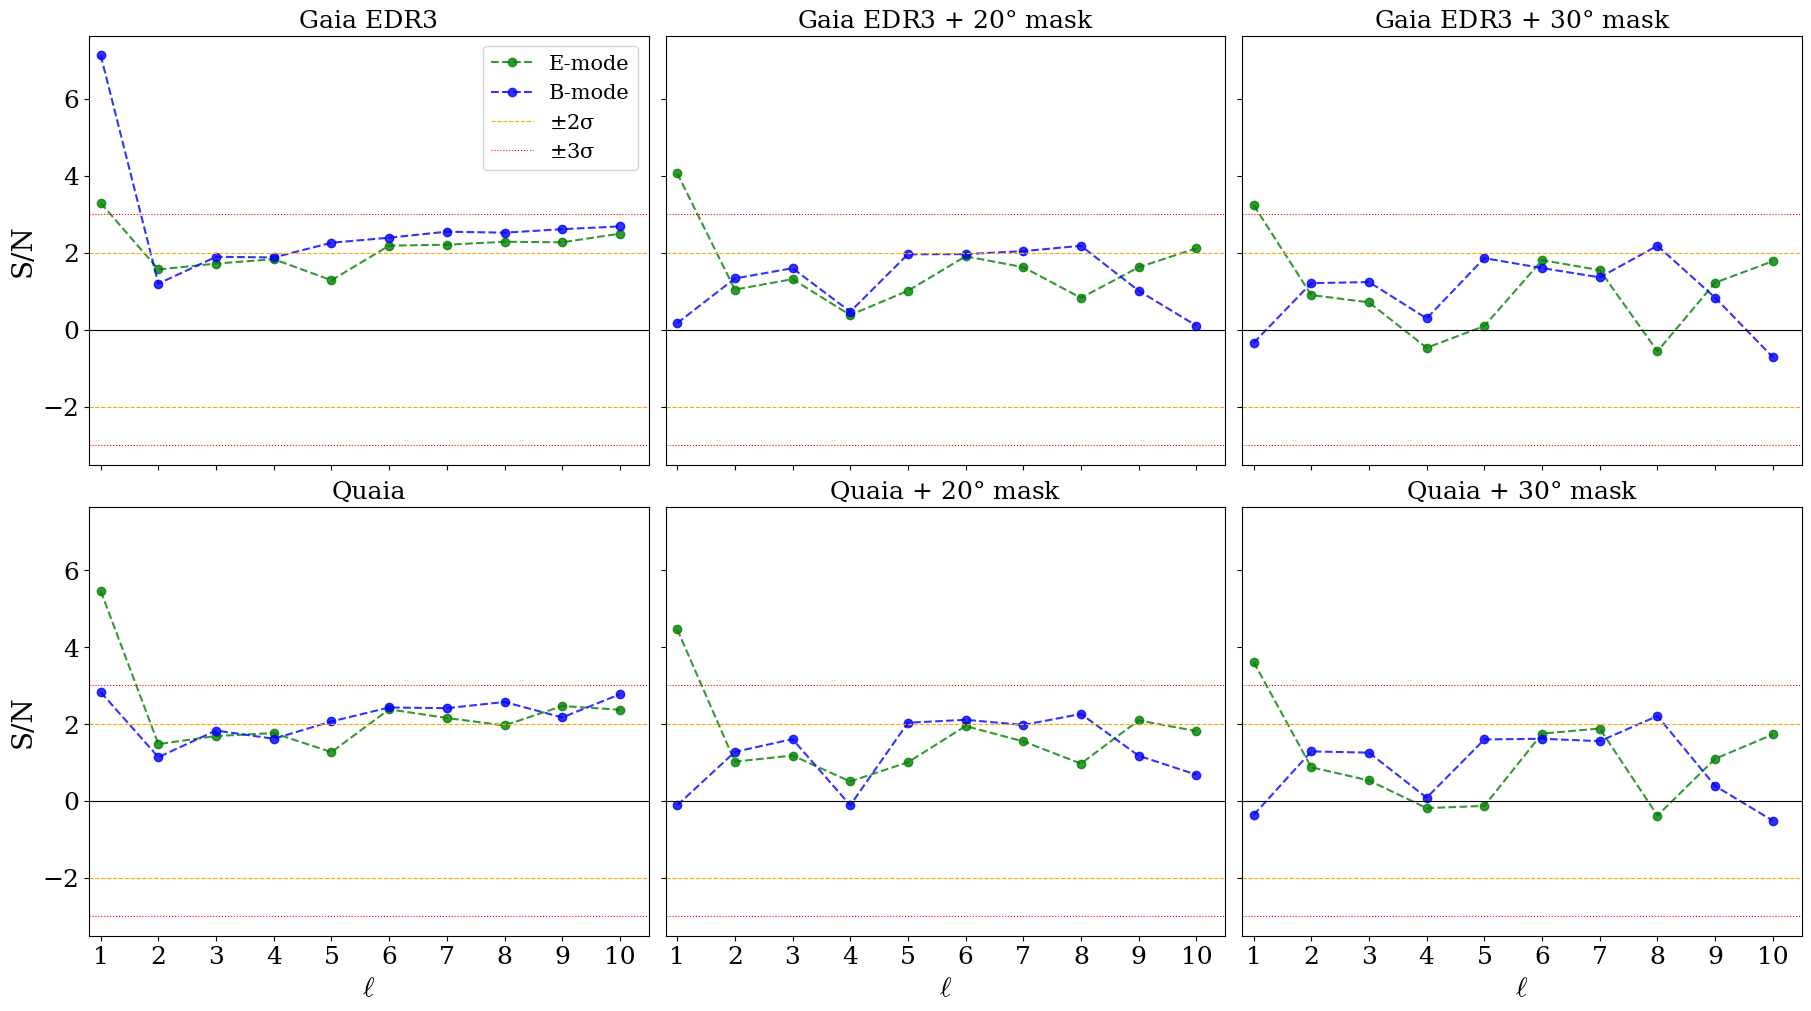

Saved: output/snr_auto_qpm_panel.pdf


In [32]:
#  2×3 SNR panel: QSO PM auto-spectrum
# Row 1: Gaia configurations | Row 2: Quaia configurations
# Cols: no galactic cut | 20° cut | 30° cut

ell_plot = ells_d1[ells_d1 <= 10]
ell_mask = ells_d1 <= 10

PANEL_CONFIGS = [
    ('gaia',            'Gaia EDR3'),
    ('gaia_galcut_20',  r'Gaia EDR3 + $20°$ mask'),
    ('gaia_galcut_30',  r'Gaia EDR3 + $30°$ mask'),
    ('quaia',           'Quaia'),
    ('quaia_galcut_20', r'Quaia + $20°$ mask'),
    ('quaia_galcut_30', r'Quaia + $30°$ mask'),
]

fig, axes = plt.subplots(2, 3, figsize=(18, 10), constrained_layout=True, sharey=True, sharex = True)

for idx, (ds, title) in enumerate(PANEL_CONFIGS):
    row = idx // 3
    col = idx  % 3
    ax  = axes[row, col]
    res = panel_results[ds]

    snr_EE = res['CL_auto_EE'][ell_mask] / res['ERR_auto_EE'][ell_mask]
    snr_BB = res['CL_auto_BB'][ell_mask] / res['ERR_auto_BB'][ell_mask]

    ax.plot(ell_plot, snr_EE, 'go--',  label='E-mode', alpha=0.8)
    ax.plot(ell_plot, snr_BB, 'bo--', label='B-mode', alpha=0.8)

    ax.axhline(0,  color='k',      lw=0.8)
    ax.axhline( 2, color='orange', lw=0.8, ls='--', label=r'$\pm2\sigma$')
    ax.axhline(-2, color='orange', lw=0.8, ls='--')
    ax.axhline( 3, color='red',    lw=0.8, ls=':',  label=r'$\pm3\sigma$')
    ax.axhline(-3, color='red',    lw=0.8, ls=':')

    ax.set_title(title, fontsize=18)
    ax.set_xlim(0.8, 10.5)
    ax.set_xticks(np.arange(1, 11))
    ax.tick_params(labelsize=18)
    #ax.grid(True, alpha=0.3)

    if col == 0:
        ax.set_ylabel(r'S/N', fontsize=20)
    if row == 1:
        ax.set_xlabel(r'$\rm \ell$', fontsize=20)

axes[0, 0].legend(loc='upper right', fontsize=15, framealpha=0.8)

import os; os.makedirs('output', exist_ok=True)
plt.savefig('output/snr_auto_qpm_panel.pdf', bbox_inches='tight')
plt.show()
print('Saved: output/snr_auto_qpm_panel.pdf')


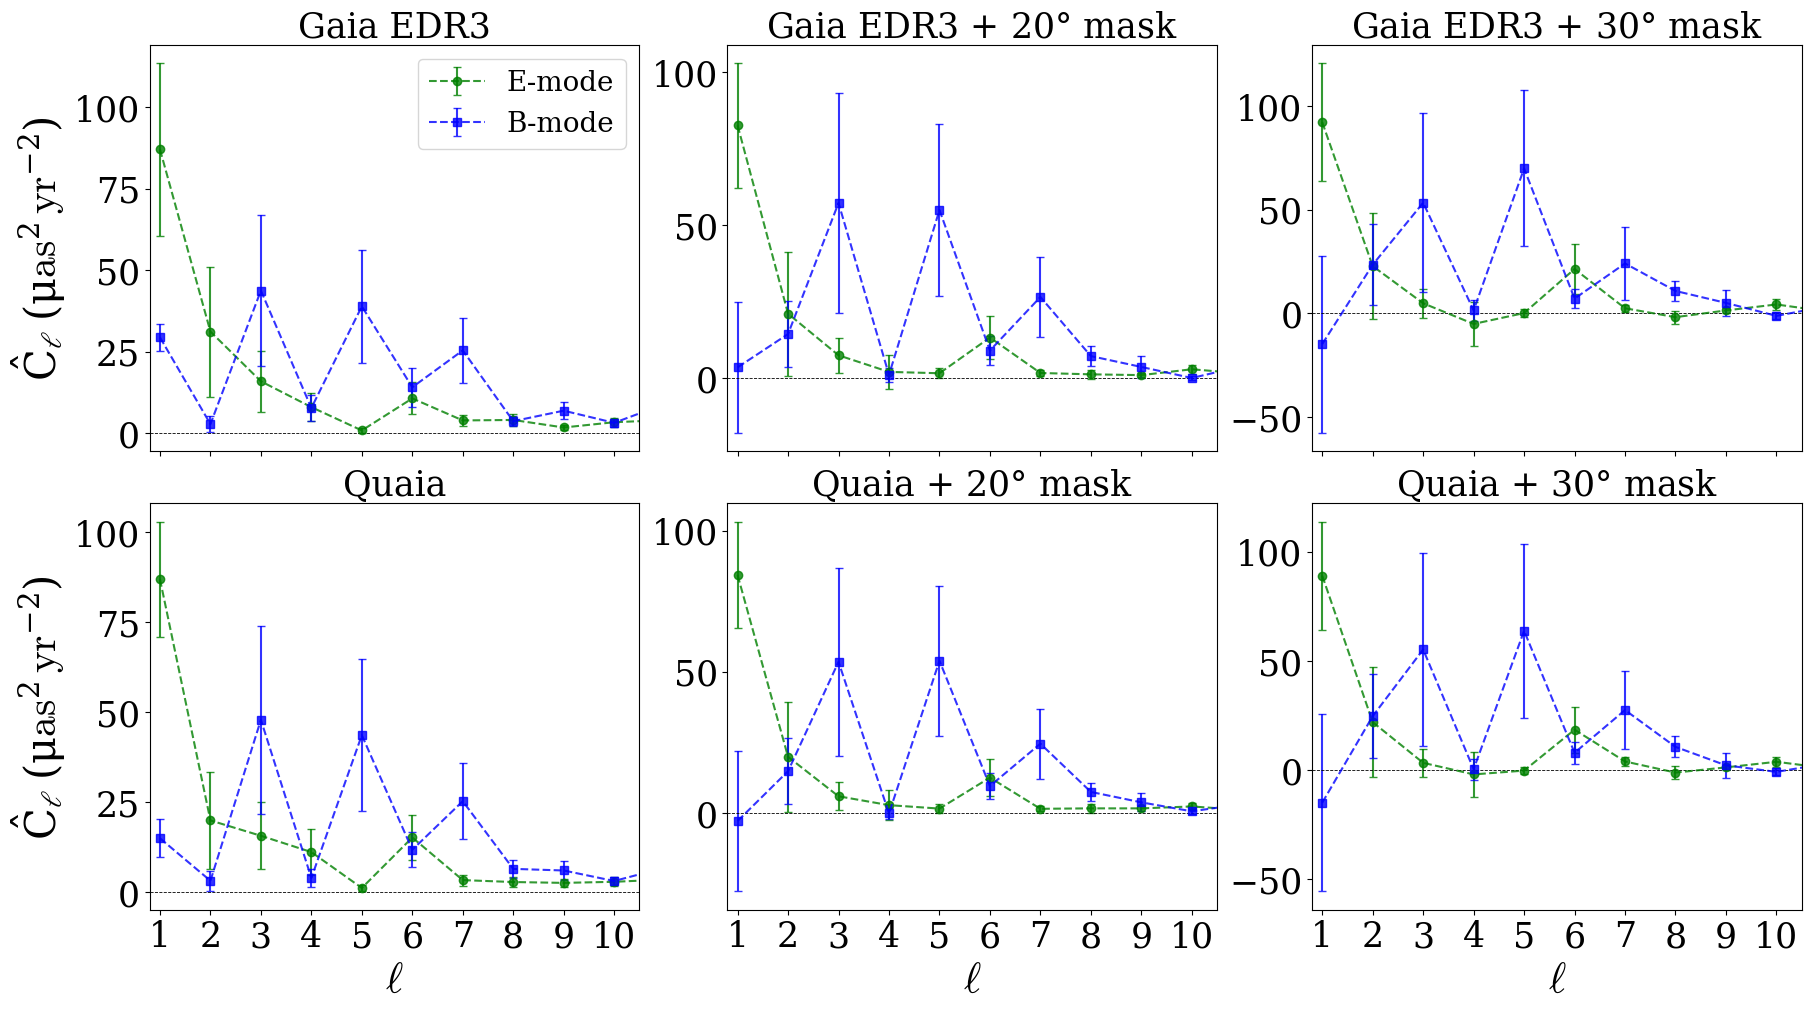

Saved: output/cl_auto_qpm_panel.pdf


In [33]:
#  2×3 power spectrum panel: QSO PM auto-spectrum (EE & BB)
# Row 1: Gaia configurations | Row 2: Quaia configurations
# Cols: no galactic mask | 20° mask | 30° mask

ell_plot = ells_d1[ell_mask_d1]

PANEL_CONFIGS = [
    ('gaia',            'Gaia EDR3'),
    ('gaia_galcut_20',  r'Gaia EDR3 + $20°$ mask'),
    ('gaia_galcut_30',  r'Gaia EDR3 + $30°$ mask'),
    ('quaia',           'Quaia'),
    ('quaia_galcut_20', r'Quaia + $20°$ mask'),
    ('quaia_galcut_30', r'Quaia + $30°$ mask'),
]

ylabel = r'$\hat{C}_\ell \;(\mu\mathrm{as}^2\,\mathrm{yr}^{-2})$'
scale  = 1e6

fig, axes = plt.subplots(2, 3, figsize=(18, 10), constrained_layout=True, sharex = True)

for idx, (ds, title) in enumerate(PANEL_CONFIGS):
    row = idx // 3
    col = idx  % 3
    ax  = axes[row, col]
    res = panel_results[ds]

    ax.errorbar(ell_plot,
                res['CL_auto_EE'][ell_mask_d1] * scale,
                yerr=res['ERR_auto_EE'][ell_mask_d1] * scale,
                fmt='go--', capsize=3, label='E-mode', alpha=0.8)
    ax.errorbar(ell_plot,
                res['CL_auto_BB'][ell_mask_d1] * scale,
                yerr=res['ERR_auto_BB'][ell_mask_d1] * scale,
                fmt='bs--', capsize=3, label='B-mode', alpha=0.8)
    ax.axhline(0, color='k', linewidth=0.6, linestyle='--')

    ax.set_title(title, fontsize=25)
    ax.set_xlim(0.8, 10.5)
    ax.set_xticks(range(1, 11))
    ax.tick_params(labelsize=25)

    if col == 0:
        ax.set_ylabel(ylabel, fontsize=30)
    if row == 1:
        ax.set_xlabel(r'$\rm \ell$', fontsize=30)
    if row == 0 and col == 0:
        ax.legend(fontsize=20)

import os; os.makedirs('output', exist_ok=True)
plt.savefig('output/cl_auto_qpm_panel.pdf', bbox_inches='tight')
plt.show()
print('Saved: output/cl_auto_qpm_panel.pdf')


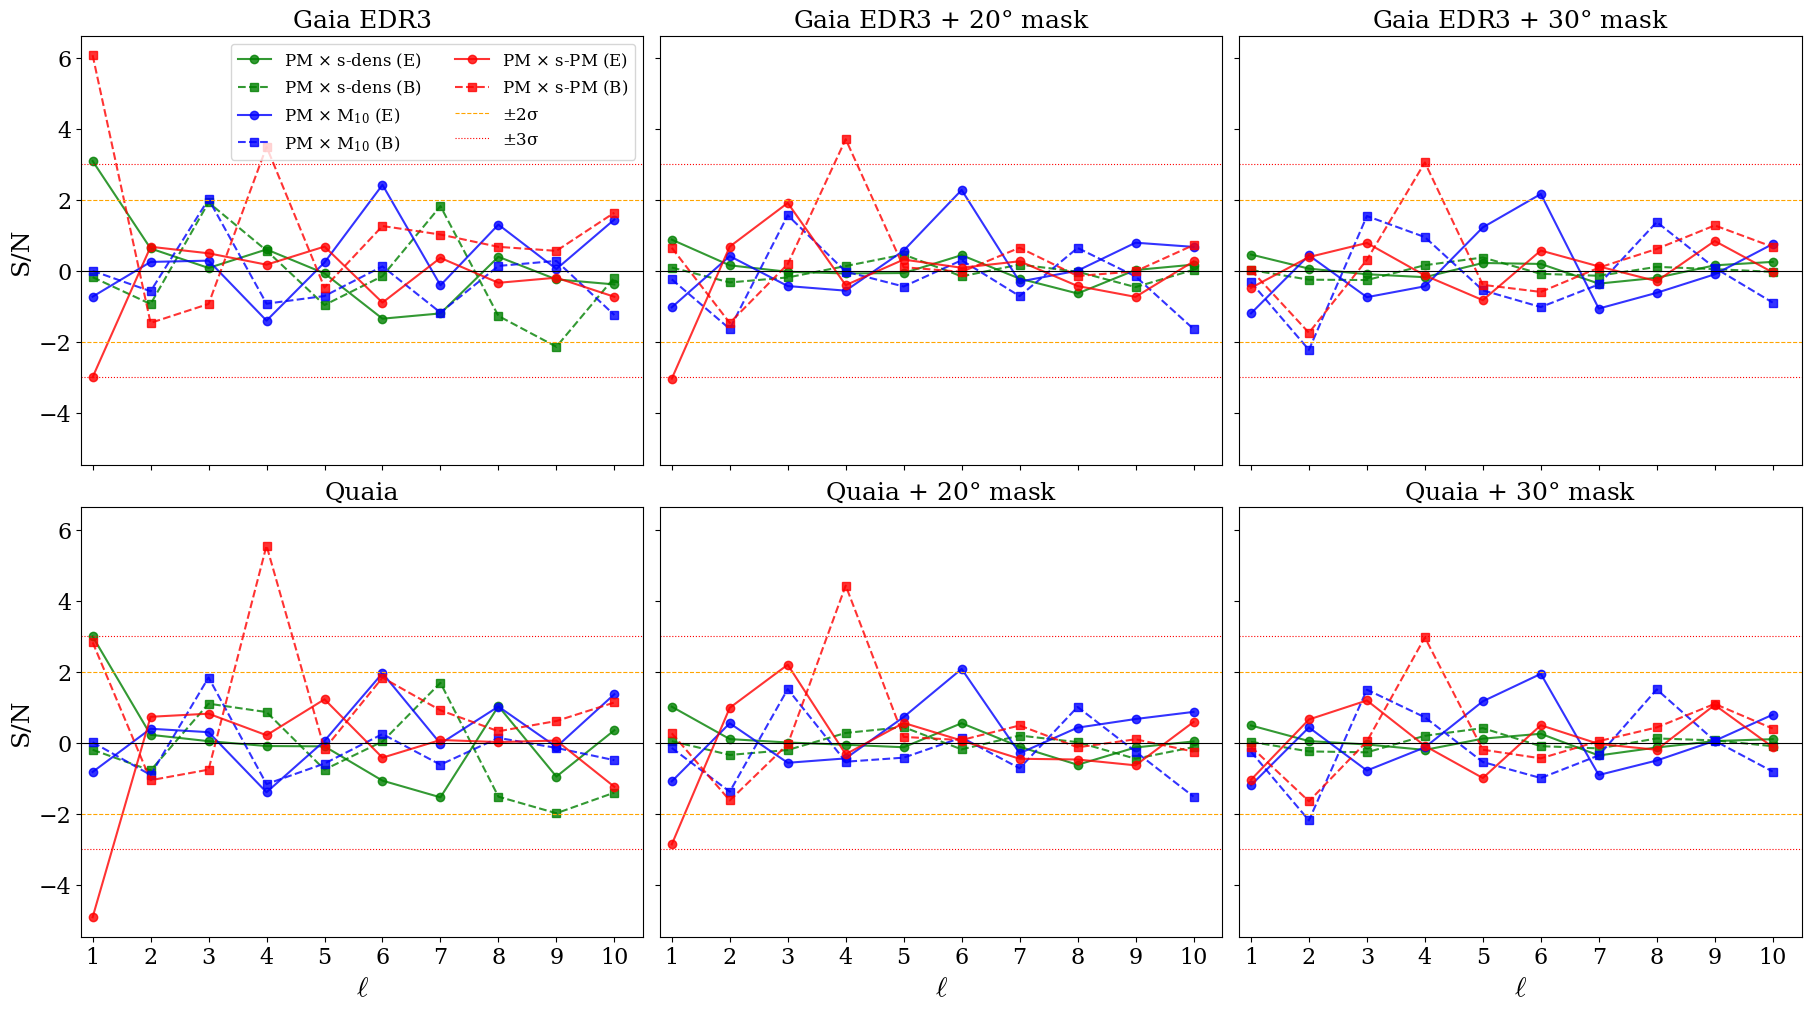

Saved: output/snr_per_ell_panel.pdf


In [34]:
#  2×3 SNR panel: all cross spectra across 6 datasets
# Row 1: Gaia configurations | Row 2: Quaia configurations
# Cols: no galactic cut | 20° cut | 30° cut

ell_plot = ells_d1[ells_d1 <= 10]
ell_mask = ells_d1 <= 10

PANEL_CONFIGS = [
    # (label, col_title)
    ('gaia',            'Gaia EDR3'),
    ('gaia_galcut_20',  r'Gaia EDR3 + $20°$ mask'),
    ('gaia_galcut_30',  r'Gaia EDR3 + $30°$ mask'),
    ('quaia',           'Quaia'),
    ('quaia_galcut_20', r'Quaia + $20°$ mask'),
    ('quaia_galcut_30', r'Quaia + $30°$ mask'),
]

fig, axes = plt.subplots(2, 3, figsize=(18, 10), constrained_layout=True, sharey=True, sharex = True)

for idx, (ds, title) in enumerate(PANEL_CONFIGS):
    row = idx // 3
    col = idx  % 3
    ax  = axes[row, col]
    res = panel_results[ds]

    snr_sdens_E = res['CL_sdens_E'][ell_mask] / res['ERR_sdens_E'][ell_mask]
    snr_sdens_B = res['CL_sdens_B'][ell_mask] / res['ERR_sdens_B'][ell_mask]
    snr_m10_E   = res['CL_m10_E'][ell_mask]   / res['ERR_m10_E'][ell_mask]
    snr_m10_B   = res['CL_m10_B'][ell_mask]   / res['ERR_m10_B'][ell_mask]
    snr_spm_EE  = res['CL_spm_EE'][ell_mask]  / res['ERR_spm_EE'][ell_mask]
    snr_spm_BB  = res['CL_spm_BB'][ell_mask]  / res['ERR_spm_BB'][ell_mask]

    ax.plot(ell_plot, snr_sdens_E, 'go-',  label=r'PM $\times$ s-dens (E)', alpha=0.8)
    ax.plot(ell_plot, snr_sdens_B, 'gs--', label=r'PM $\times$ s-dens (B)', alpha=0.8)
    ax.plot(ell_plot, snr_m10_E,   'bo-',  label=r'PM $\times$ $M_{10}$ (E)', alpha=0.8)
    ax.plot(ell_plot, snr_m10_B,   'bs--', label=r'PM $\times$ $M_{10}$ (B)', alpha=0.8)
    ax.plot(ell_plot, snr_spm_EE,  'ro-',  label=r'PM $\times$ s-PM (E)', alpha=0.8)
    ax.plot(ell_plot, snr_spm_BB,  'rs--', label=r'PM $\times$ s-PM (B)', alpha=0.8)

    ax.axhline(0,  color='k',      lw=0.8)
    ax.axhline( 2, color='orange', lw=0.8, ls='--', label = r'$\pm 2\sigma$')
    ax.axhline(-2, color='orange', lw=0.8, ls='--')
    ax.axhline( 3, color='red',    lw=0.8, ls=':', label = r'$\pm 3\sigma$')
    ax.axhline(-3, color='red',    lw=0.8, ls=':')

    ax.set_title(title, fontsize=18)
    ax.set_xlim(0.8, 10.5)
    ax.set_xticks(np.arange(1, 11))
    ax.tick_params(labelsize=16)
    #ax.grid(True, alpha=0.3)

    if col == 0:
        ax.set_ylabel(r'S/N', fontsize=18)
    if row == 1:
        ax.set_xlabel(r'$\rm \ell$', fontsize=20)

# Single legend on first panel
axes[0, 0].legend(loc='upper right', fontsize=12, framealpha=0.8, ncol=2)

import os; os.makedirs('output', exist_ok=True)
plt.savefig('output/snr_per_ell_panel.pdf', bbox_inches='tight')
plt.show()
print('Saved: output/snr_per_ell_panel.pdf')


/home/phuy2808/Astrophysis/Intern_apc/myenv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


gaia: noise done
gaia_galcut_20: noise done
gaia_galcut_30: noise done
quaia: noise done
quaia_galcut_20: noise done
quaia_galcut_30: noise done


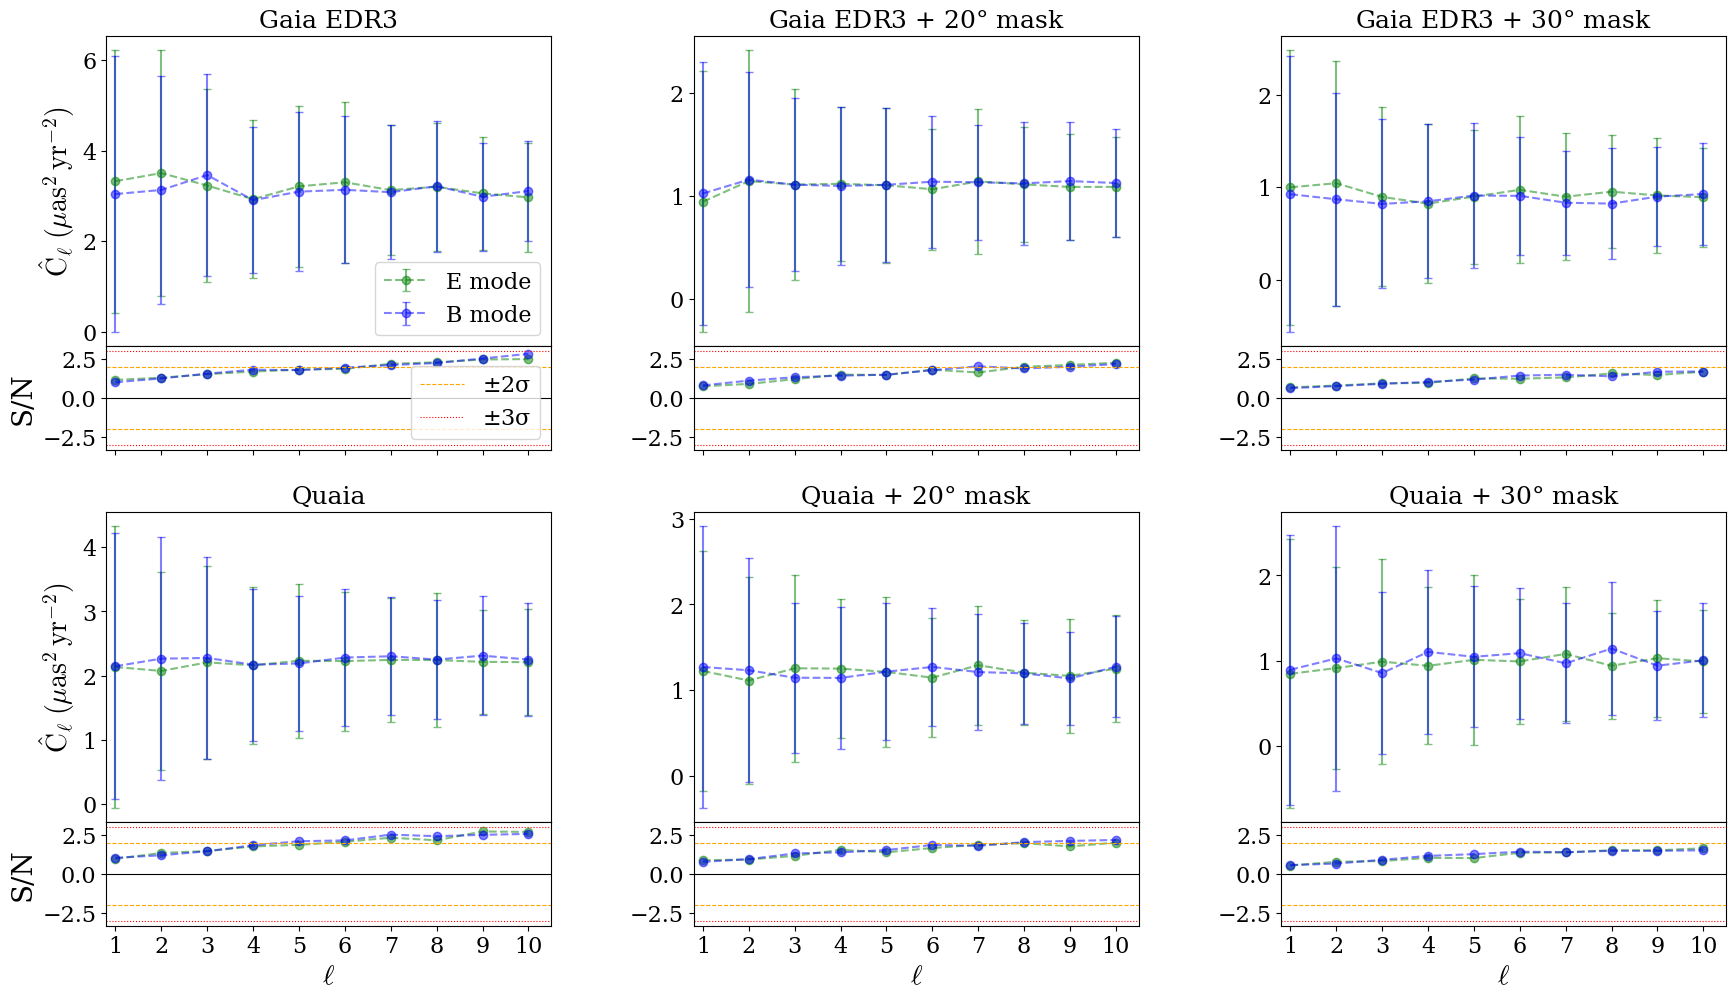

Saved: output/auto_cl_noise_snr_panel.pdf


In [35]:
from sbi_qpm.sbi_setup import precompute_noise_cholesky, generate_pixel_noise
import matplotlib.gridspec as gridspec

# ── Auto-spectrum: data vs forward-model pixel noise ─────────────────────────
# Pixel noise = Cholesky draw from per-pixel 2x2 noise covariance.
# N_NOISE realisations → mean noise Cl + std error bar.
# SNR panel = noise_EE / std(noise_EE) per ell.

N_NOISE  = 200
ell_plot = ells_d1[ells_d1 <= 10]
ell_mask = ells_d1 <= 10
scale    = 1e6  # uas^2/yr^2

PANEL_CONFIGS = [
    ('gaia',            'Gaia EDR3'),
    ('gaia_galcut_20',  r'Gaia EDR3 + $20°$ mask'),
    ('gaia_galcut_30',  r'Gaia EDR3 + $30°$ mask'),
    ('quaia',           'Quaia'),
    ('quaia_galcut_20', r'Quaia + $20°$ mask'),
    ('quaia_galcut_30', r'Quaia + $30°$ mask'),
]

# Two row-groups; within each group SNR panel is 1/4 height of Cl panel, no gap
fig = plt.figure(figsize=(18, 10))
outer_gs = gridspec.GridSpec(2, 1, figure=fig, hspace=0.15,
                             top=0.95, bottom=0.06, left=0.07, right=0.97)

axes = np.empty((4, 3), dtype=object)
for g in range(2):
    inner_gs = gridspec.GridSpecFromSubplotSpec(
        2, 3, subplot_spec=outer_gs[g],
        hspace=0, height_ratios=[3, 1], wspace=0.32,
    )
    for c in range(3):
        axes[g * 2,     c] = fig.add_subplot(inner_gs[0, c])
        axes[g * 2 + 1, c] = fig.add_subplot(inner_gs[1, c],
                                              sharex=axes[g * 2, c])

for idx, (ds, title) in enumerate(PANEL_CONFIGS):
    col      = idx % 3
    row_base = (idx // 3) * 2
    ax_cl  = axes[row_base,     col]
    ax_snr = axes[row_base + 1, col]

    res    = panel_results[ds]
    CL_EE  = res['CL_auto_EE'][ell_mask] * scale
    CL_BB  = res['CL_auto_BB'][ell_mask] * scale
    ERR_EE = res['ERR_auto_EE'][ell_mask] * scale
    ERR_BB = res['ERR_auto_BB'][ell_mask] * scale

    # ── Noise Cl from forward-model pixel noise realisations ──────────────────
    gaia_ds   = quaia if 'quaia' in ds else gaia
    galcut_ds = 20 if '20' in ds else (30 if '30' in ds else 0)

    pix_n = compute_pixel_stats(
        gaia_ds['ra'].values, gaia_ds['dec'].values,
        gaia_ds['pmra'].values, gaia_ds['pmdec'].values,
        gaia_ds['pmra_error'].values, gaia_ds['pmdec_error'].values,
        gaia_ds['pmra_pmdec_corr'].values,
        nside=nside, galcut=galcut_ds,
    )
    mask_n = (pix_n['mask'] & mask_star_pm & mask_sdens & mask_m10).astype(float)
    apod_n = nmt.mask_apodization(mask_n, APOD_SCALE, APOD_TYPE)

    sig_ra  = np.where(pix_n['mask'] & (pix_n['sig_pmra_wm']  > 0), pix_n['sig_pmra_wm'],  0.0)
    sig_dec = np.where(pix_n['mask'] & (pix_n['sig_pmdec_wm'] > 0), pix_n['sig_pmdec_wm'], 0.0)
    corr_n  = np.where(pix_n['mask'], pix_n['pm_corr_wm'], 0.0)

    L11, L21, L22, valid_pix = precompute_noise_cholesky(
        sig_ra, sig_dec, corr_n, pix_n['mask'].astype(bool), npix
    )

    nr0, nd0 = generate_pixel_noise(L11, L21, L22, valid_pix, npix)
    f_n0 = nmt.NmtField(apod_n, [-nd0, nr0], spin=1)
    ws_n = nmt.NmtWorkspace()
    ws_n.compute_coupling_matrix(f_n0, f_n0, bins_d1)

    noise_sims_EE = np.zeros((N_NOISE, ell_mask.sum()))
    noise_sims_BB = np.zeros((N_NOISE, ell_mask.sum()))
    for k in range(N_NOISE):
        nr, nd  = generate_pixel_noise(L11, L21, L22, valid_pix, npix)
        f_nk    = nmt.NmtField(apod_n, [-nd, nr], spin=1)
        cl_nk   = ws_n.decouple_cell(nmt.compute_coupled_cell(f_nk, f_nk))
        noise_sims_EE[k] = cl_nk[0][ell_mask]
        noise_sims_BB[k] = cl_nk[3][ell_mask]

    noise_EE     = noise_sims_EE.mean(axis=0) * scale
    noise_BB     = noise_sims_BB.mean(axis=0) * scale
    err_noise_EE = noise_sims_EE.std(axis=0)  * scale
    err_noise_BB = noise_sims_BB.std(axis=0)  * scale
    print(f'{ds}: noise done')

    # ── Upper panel: Cl ───────────────────────────────────────────────────────
    ax_cl.errorbar(ell_plot, noise_EE, yerr=err_noise_EE, fmt='go--', capsize=3,
                   alpha=0.5, label='E mode')
    ax_cl.errorbar(ell_plot, noise_BB, yerr=err_noise_BB, fmt='bo--', capsize=3,
                   alpha=0.5, label='B mode')
    ax_cl.set_title(title, fontsize=18)
    if col == 0:
        ax_cl.set_ylabel(r'$\rm \hat{C}_\ell \;(\mu\mathrm{as}^2\,\mathrm{yr}^{-2})$', fontsize=20)
    ax_cl.set_xlim(0.8, 10.5); ax_cl.set_xticks(range(1, 11))
    ax_cl.tick_params(labelsize=16, labelbottom=False)
    if col == 0 and row_base == 0:
        ax_cl.legend(fontsize=16)

    # ── Lower panel: SNR of noise Cl ─────────────────────────────────────────
    snr_noise_EE = noise_EE / err_noise_EE
    snr_noise_BB = noise_BB / err_noise_BB
    ax_snr.plot(ell_plot, snr_noise_EE, 'go--', alpha=0.5)
    ax_snr.plot(ell_plot, snr_noise_BB, 'bo--', alpha=0.5)
    ax_snr.axhline( 0, color='k',      lw=0.8)
    ax_snr.axhline( 2, color='orange', lw=0.8, ls='--', label=r'$\pm2\sigma$')
    ax_snr.axhline(-2, color='orange', lw=0.8, ls='--')
    ax_snr.axhline( 3, color='red',    lw=0.8, ls=':', label = r'$\pm3\sigma$')
    ax_snr.axhline(-3, color='red',    lw=0.8, ls=':')
    if col == 0:
        ax_snr.set_ylabel(r'S/N', fontsize=20)
    if row_base == 2:
        ax_snr.set_xlabel(r'$\rm \ell$', fontsize=20)
    ax_snr.set_xlim(0.8, 10.5); ax_snr.set_xticks(range(1, 11))
    ax_snr.tick_params(labelsize=16, labelbottom=(row_base == 2))
    if col == 0 and row_base == 0:
        ax_snr.legend(fontsize=16)

import os
os.makedirs('output', exist_ok=True)
plt.savefig('output/auto_cl_noise_snr_panel.pdf', bbox_inches='tight')
plt.show()
print('Saved: output/auto_cl_noise_snr_panel.pdf')